# Step 1 — Femur and tracked-marker scene model
Uses the actual supplied femur mesh and the exact selected marker coordinates from your notebook. Requires NumPy and Matplotlib.

**Preview limitation:** the upload does not contain a saved femur/reference workspace pose. The default preview uses CT = workspace and an illustrative reference mounting at (100, 0, 0) mm. This mounting is not a recovered design choice. Triangle edges represent marker geometry, not manufactured brackets.

Run all cells for the preview. For your session-specific scene, run the definitions in your assignment notebook after Step 2 and call `plot_scene(session, patch_id=0)`. The approximate femur pose is `F_W_ref @ inverse(F0_reg)`; the hidden true pose is not available. Pointer and reference poses then come directly from the session. The mesh is embedded, so no extra data file is required.

| Body | Marker 1 | Marker 2 | Marker 3 |
|---|---|---|---|
| Reference | (-45,-25,0) | (50,-30,0) | (0,20,0) |
| Pointer | (-50,-20,0) | (50,-20,0) | (0,30,0) |

All marker coordinates are local, in mm. Pointer tip: (0,0,-150). Tracker pose: Rx(pi), translation (0,0,1900) mm. Visibility shown here is geometric only; use the supplied session visibility checks for each patch.

AI assistance: model and plotting code generated by ChatGPT from the prompt “use these; create a model for step 1 based on our selected marker positions and the femur position.” Retain this disclosure for the assignment report.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

REF = np.array([[-45,-25,0],[50,-30,0],[0,20,0]], dtype=float)
PTR = np.array([[-50,-20,0],[50,-20,0],[0,30,0]], dtype=float)
TIP = np.array([0,0,-150.])
CAMERA = np.diag([1.,-1.,-1.,1.]); CAMERA[:3,3] = [0,0,1900]

def matrix(F):
    """Convert a course Frame or 4x4 array to a homogeneous matrix."""
    if hasattr(F, 'R'):
        out=np.eye(4); out[:3,:3]=F.R.matrix; out[:3,3]=F.p.vec.ravel(); return out
    return np.asarray(F,dtype=float)

def transform(F, points):
    """Transform Nx3 local points to workspace coordinates."""
    return np.asarray(points) @ F[:3,:3].T + F[:3,3]

def plot_scene(session=None, patch_id=0):
    """Plot real mesh and selected marker geometry, using session nominal poses if supplied.
    Returns a Matplotlib figure. No server calls that collect data are made.
    Femur pose with a session is an approximation: F_W_CT = F_W_ref inv(F0_reg).
    Without a session, CT equals workspace and reference mounting is illustrative.
    """
    if session is None:
        femur=np.eye(4)
        ref=np.eye(4); ref[:3,3]=[100,0,0] # illustration only, not a selected mounting
        ptr=np.eye(4); ptr[:3,:3]=np.array(BOXES[patch_id]['rotation_local_to_world'])
        tip=np.array(BOXES[patch_id]['centroid_world'])
        ptr[:3,3]=tip-ptr[:3,:3]@TIP
        title='Illustrative mounting | femur CT frame = workspace'
    else:
        ref=matrix(session.nominal_reference_pose())
        femur=ref@np.linalg.inv(matrix(session.initial_registration_guess()))
        ptr=matrix(session.nominal_pointer_pose(patch_id))
        title='Session nominal scene | approximate femur pose from initial registration'
    V=transform(femur,VERTICES); a=transform(ref,REF); b=transform(ptr,PTR); tip=transform(ptr,TIP[None,:])[0]
    fig=plt.figure(figsize=(13,7),facecolor='white')
    ax=fig.add_subplot(121,projection='3d'); wide=fig.add_subplot(122,projection='3d')
    for axis in [ax,wide]:
        axis.add_collection3d(Poly3DCollection(V[TRIANGLES],facecolor='#c4ced7',edgecolor='none',alpha=.65))
        for pts,color,name in [(a,'#168779','Reference'),(b,'#db7140','Pointer')]:
            axis.scatter(*pts.T,color=color,s=35,label=name+' markers')
            closed=np.vstack([pts,pts[0]]); axis.plot(*closed.T,color=color,lw=2)
        axis.plot(*np.vstack([tip,ptr[:3,3]]).T,color='#db7140',lw=3)
        axis.scatter(*tip,color='#222222',s=30,label='Pointer tip')
        axis.set(xlabel='Workspace x (mm)',ylabel='Workspace y (mm)',zlabel='Workspace z (mm)')
        axis.view_init(elev=22,azim=-60)
    for pts,prefix in [(a,'R'),(b,'P')]:
        for i,p in enumerate(pts): ax.text(*(p+3),f'{prefix}{i+1}',fontsize=9)
    allpts=np.vstack([V,a,b,tip]); mid=(allpts.min(0)+allpts.max(0))/2; r=np.ptp(allpts,axis=0).max()*.62
    ax.set(xlim=(mid[0]-r,mid[0]+r),ylim=(mid[1]-r,mid[1]+r),zlim=(mid[2]-r,mid[2]+r)); ax.set_box_aspect([1,1,1]); ax.set_title('Femur, reference body and pointer')
    # Frustum dimensions from Step 1: 1000 mm square at 1000 mm; 2000 at 2200.
    near=np.array([[-500,-500,1000],[500,-500,1000],[500,500,1000],[-500,500,1000]])
    far=np.array([[-1000,-1000,2200],[1000,-1000,2200],[1000,1000,2200],[-1000,1000,2200]])
    near=transform(CAMERA,near); far=transform(CAMERA,far)
    for ring in [near,far]:
        ring=np.vstack([ring,ring[0]]); wide.plot(*ring.T,color='#5681ac',alpha=.6)
    for p,q in zip(near,far): wide.plot(*np.vstack([p,q]).T,color='#5681ac',alpha=.4)
    wide.scatter(0,0,1900,marker='s',s=55,color='#23496e',label='Tracker')
    wide.quiver(0,0,1900,0,0,-350,color='#23496e',arrow_length_ratio=.15)
    wide.set(xlim=(-1100,1100),ylim=(-1100,1100),zlim=(-400,2000)); wide.set_box_aspect([1,1,1.1]); wide.set_title('Camera and nominal viewing volume')
    ax.legend(loc='upper left',fontsize=8)
    fig.suptitle('CIS I Assignment 3 | Step 1 scene model',fontsize=17)
    fig.text(.5,.025,title+' | schematic supports; all dimensions in mm',ha='center',fontsize=10)
    fig.subplots_adjust(left=.01,right=.96,bottom=.12,top=.85,wspace=.1)
    return fig


In [2]:
VERTICES=np.array([[-23.786148, -16.420282, -48.229988], [-20.396912, -12.622053, -49.394562], [-23.783207, -9.689573, -49.930054], [-15.800093, -10.141426, -48.594055], [-20.002115, -22.54809, -46.172775], [-30.334402, -19.718163, -45.430111], [-27.396872, -19.596577, -46.544811], [-23.536985, -19.819441, -46.959457], [-20.336811, -20.010075, -47.192352], [-16.767815, -19.720238, -46.679176], [-29.955103, -16.385382, -47.107235], [-27.889812, -16.514002, -47.133274], [-20.110569, -16.44264, -48.20013], [-16.44841, -16.699795, -47.412849], [-13.529147, -16.405663, -47.259239], [-35.702847, -12.38602, -45.14761], [-33.936966, -12.513238, -46.210732], [-29.944088, -12.560177, -47.197044], [-27.496243, -12.727137, -48.132023], [-23.977119, -12.596711, -48.630154], [-20.145435, -12.847064, -46.920708], [-12.807314, -13.11193, -47.396137], [-9.704149, -12.718398, -46.561569], [-33.640198, -9.134289, -46.133492], [-30.626936, -8.92119, -47.400562], [-27.420288, -9.067814, -48.281528], [-20.052992, -9.161464, -48.999603], [-12.928831, -9.491612, -47.82164], [-9.493683, -9.524945, -46.753284], [-7.958556, -9.30188, -45.406193], [-30.055374, -5.259793, -46.720917], [-27.12052, -4.877913, -48.084263], [-23.835712, -5.082419, -47.43272], [-20.021643, -5.169733, -48.655556], [-16.576967, -5.792709, -47.751953], [-12.977015, -6.09092, -47.705605], [-10.305445, -6.504159, -46.746964], [-27.105272, -1.878712, -46.52359], [-23.944715, -2.099434, -47.682358], [-20.32943, -1.743476, -47.148918], [-16.629755, -1.900172, -47.323654], [-13.069265, -2.469976, -46.643593], [-20.032549, -25.838306, -43.115608], [-30.280787, -22.984219, -43.162029], [-27.214211, -23.416567, -43.741081], [-23.855099, -23.710838, -43.856464], [-16.744041, -23.45867, -44.089203], [-12.915039, -23.240583, -43.643974], [-10.277787, -22.402441, -42.79221], [-33.568928, -19.439606, -43.188908], [-11.873021, -19.808933, -44.501541], [-8.896863, -19.692671, -43.715408], [-36.57272, -15.913729, -42.676018], [-34.424362, -16.436218, -44.499569], [-9.20481, -16.538691, -44.579388], [-38.54789, -12.539969, -41.219696], [-37.568459, -12.67085, -42.768551], [-6.081568, -12.733372, -43.34885], [-37.012756, -9.160524, -43.248081], [-5.835159, -9.597781, -43.338749], [-34.298199, -5.422415, -44.320053], [-6.369446, -6.10493, -43.217613], [-33.76416, -1.626849, -43.126858], [-31.167904, -1.467315, -44.259594], [-9.703901, -2.748822, -44.039055], [-27.262016, 1.976829, -43.985123], [-23.808338, 2.086092, -44.791176], [-20.215937, 1.639537, -45.006294], [-16.522177, 1.632521, -45.329338], [-13.013578, 1.121999, -44.211872], [-20.018885, -28.990536, -39.356815], [-30.303263, -26.291149, -39.729591], [-26.938992, -27.283566, -39.893841], [-23.739492, -27.339813, -40.410172], [-16.350986, -26.986021, -41.037174], [-12.927554, -25.880945, -40.998356], [-10.658375, -25.311502, -40.137608], [-34.322018, -23.464518, -39.474136], [-8.348989, -22.776432, -40.688328], [-37.124477, -19.566816, -39.5564], [-6.229956, -19.6703, -41.256229], [-39.157642, -15.852404, -39.497311], [-4.873273, -16.071465, -41.221516], [-3.04618, -15.988908, -39.470985], [-39.38213, -12.491071, -39.748631], [-2.267064, -12.848255, -38.591816], [-39.44104, -9.381376, -40.516762], [-2.094476, -9.192095, -38.985641], [-38.09552, -4.646038, -40.700138], [-3.190952, -6.127591, -39.350075], [-36.733265, -1.236372, -40.421391], [-5.872362, -2.282853, -40.492455], [-36.000568, 1.006247, -39.440784], [-34.251778, 1.720316, -40.20546], [-31.304941, 3.244208, -40.699139], [-9.66301, 1.200921, -41.992405], [-30.445185, 5.432925, -39.518013], [-27.14959, 5.347118, -40.882919], [-23.698503, 5.741667, -41.673851], [-20.13615, 5.713175, -41.415371], [-16.527719, 5.14688, -42.467045], [-13.127829, 4.836402, -41.469025], [-29.958029, -28.923151, -35.709213], [-26.781969, -29.689142, -36.141621], [-23.300478, -30.310768, -36.757935], [-19.820684, -30.038877, -37.668106], [-16.601355, -29.392159, -37.515488], [-33.538555, -26.680321, -36.014305], [-9.993793, -26.218287, -38.209969], [-37.116013, -23.325731, -35.431393], [-6.440058, -23.236841, -37.954216], [-38.856747, -19.978693, -35.890381], [-4.255683, -20.090734, -38.297001], [-2.128359, -19.142372, -35.980305], [-39.705078, -16.22727, -36.352684], [-0.460164, -15.73069, -35.237125], [-39.957458, -12.446911, -36.960106], [-0.709281, -12.691541, -35.072899], [-40.293327, -8.837272, -37.235519], [-1.461735, -8.973471, -35.752071], [-40.187469, -4.942307, -37.225128], [-2.564224, -5.469567, -36.614639], [-39.170357, -1.353936, -36.982311], [-3.561532, -3.107742, -37.222309], [-37.007713, 1.758003, -37.37014], [-5.87618, 0.851704, -37.603729], [-33.651054, 5.030641, -36.92067], [-9.421652, 4.733839, -37.985413], [-27.02652, 8.169273, -37.068237], [-23.788496, 8.519118, -37.988789], [-19.689901, 9.049597, -37.378719], [-16.464643, 8.366294, -38.598869], [-13.658712, 7.948476, -38.169914], [-16.956102, 9.983766, -36.901646], [-26.590473, -31.601952, -32.559303], [-23.399286, -32.093998, -32.788734], [-20.462866, -32.066799, -33.623543], [-17.0686, -31.387819, -33.933178], [-30.799622, -29.761541, -32.569839], [-12.934222, -30.020533, -34.226509], [-9.774784, -28.579435, -33.773418], [-34.204456, -27.707197, -32.371174], [-6.592484, -25.618507, -34.280308], [-37.338394, -24.076874, -33.331627], [-2.508463, -22.398043, -33.597], [-39.975662, -20.273933, -32.716026], [-0.825349, -19.545971, -32.551456], [-39.768394, -16.739302, -33.276222], [0.000949, -16.234076, -33.310303], [0.131099, -12.830458, -33.061268], [-40.290997, -9.223263, -33.51503], [-1.831999, -8.785814, -32.754398], [-42.344257, -5.704601, -32.409241], [-3.09312, -5.574582, -33.798286], [-40.261032, -0.923866, -34.137573], [-3.715662, -2.862944, -34.681038], [-38.581097, 1.771703, -33.745544], [-5.44965, 1.37642, -34.709515], [-33.815453, 6.114002, -34.464314], [-6.924168, 4.649458, -33.543606], [-30.476158, 7.321663, -35.724827], [-27.418856, 9.583179, -34.415722], [-13.00246, 8.671404, -35.193645], [-9.874177, 7.887657, -33.263695], [-23.452629, 10.447027, -34.515408], [-20.171021, 11.228201, -34.49427], [-16.817711, 10.571577, -34.85228], [-26.946163, -31.934628, -30.003302], [-23.509827, -32.740841, -30.411812], [-20.050571, -32.632507, -30.882853], [-16.729525, -31.921761, -31.095991], [-30.349239, -30.618269, -29.359297], [-12.281596, -30.55039, -30.85141], [-10.281534, -29.352673, -30.814653], [-35.250999, -27.272766, -29.107729], [-5.832138, -26.478434, -30.509892], [-38.466267, -23.958916, -29.984867], [-1.735662, -22.538662, -29.026304], [-41.096577, -20.187393, -28.982027], [-0.300522, -19.620594, -29.419161], [-41.829697, -16.141539, -29.895771], [0.125294, -16.276146, -30.019466], [-40.336964, -12.851084, -30.592213], [0.27795, -12.438807, -30.354546], [-43.368515, -8.340121, -29.15826], [-0.246555, -8.863216, -29.894848], [-43.605526, -5.003905, -28.315365], [-1.664459, -5.578869, -30.438765], [-42.584248, -2.343856, -29.494864], [-41.225895, -0.153619, -30.103226], [-2.948894, -3.157855, -30.934462], [27.545267, -1.364655, -28.731033], [-39.049698, 2.981468, -29.914194], [-5.516135, 1.13429, -31.901674], [24.559544, 2.18623, -29.462851], [27.651352, 2.384062, -30.493666], [30.05241, 2.436162, -28.853943], [-36.776787, 5.348766, -29.842419], [-6.848401, 4.461972, -30.925756], [24.33968, 4.830681, -30.244848], [27.470779, 5.416708, -29.925438], [-33.592903, 7.613504, -30.878462], [-31.048323, 9.237131, -30.8279], [-27.399612, 10.476454, -30.543114], [-13.395947, 9.635848, -32.4856], [-9.602827, 8.062674, -29.579828], [24.007168, 8.56403, -30.579475], [27.663231, 8.859051, -30.323284], [-23.124914, 11.692946, -31.06739], [-19.922405, 11.999646, -31.168922], [-16.643414, 11.461282, -31.449503], [20.501692, 12.234935, -31.337318], [24.551336, 11.925952, -31.016329], [26.779989, 11.768921, -29.6415], [16.637875, 16.360016, -31.076422], [19.644846, 16.185293, -31.222382], [13.155482, 18.990479, -30.627693], [15.529992, 19.060669, -31.25518], [18.712755, 18.788792, -30.004993], [15.810811, 20.481777, -30.142902], [-30.443695, -30.731064, -26.018047], [-27.129843, -32.08424, -26.789618], [-23.338394, -32.83205, -27.270372], [-19.971958, -32.789158, -27.561087], [-16.484966, -32.351509, -27.838305], [-33.117783, -29.235703, -25.821079], [-12.347826, -31.064383, -27.284933], [-9.142202, -29.496454, -26.615923], [-36.531822, -26.460556, -26.424524], [-5.452005, -26.863279, -26.461014], [-39.315014, -23.460896, -26.75876], [-2.200003, -23.353069, -24.855715], [-41.189571, -20.3638, -25.478579], [0.054747, -19.731853, -26.067219], [1.362257, -16.217697, -26.501404], [-44.006165, -12.461151, -25.238657], [1.791228, -12.594996, -26.843021], [20.149708, -9.641974, -21.966434], [-44.45713, -8.6527, -24.758423], [1.769565, -8.809111, -26.968304], [18.425684, -7.983624, -23.320192], [20.05365, -8.321571, -23.178907], [23.181099, -8.660584, -24.559719], [30.009689, -6.994381, -24.004328], [-43.675861, -5.15465, -24.640871], [1.713074, -6.124394, -26.632187], [21.21076, -5.493764, -24.546955], [23.772085, -4.8686, -26.117647], [27.093065, -5.006836, -25.928055], [30.017464, -4.897404, -26.181211], [32.315308, -4.054646, -24.056095], [-41.995171, -0.982898, -25.665457], [-0.968144, -2.961326, -27.737434], [24.071032, -1.911817, -27.141899], [31.48583, -0.765737, -26.152973], [-39.436745, 2.764033, -26.064793], [-4.125288, 1.521661, -28.674482], [21.652094, 1.917831, -27.209425], [31.133686, 2.125358, -26.946808], [-37.112274, 5.408328, -26.726267], [-5.447267, 4.5388, -27.521933], [20.551453, 4.935441, -28.116495], [31.290352, 5.925145, -27.430286], [-35.229294, 7.10856, -27.097658], [-33.81612, 8.045625, -27.384989], [-30.36548, 10.042838, -27.62133], [-10.164519, 8.691251, -25.718742], [19.723803, 8.632635, -28.569103], [30.888832, 9.073206, -27.589209], [-26.467739, 11.696942, -26.630114], [-23.473091, 12.262573, -27.29344], [-20.590399, 12.497706, -27.494164], [-16.674683, 12.090671, -27.800152], [-13.93174, 10.895544, -27.530579], [16.088097, 12.373021, -29.027288], [27.15888, 14.759735, -27.597492], [30.21603, 12.039746, -26.75374], [13.221253, 15.769839, -29.497631], [24.020407, 16.078901, -28.296732], [11.761127, 18.950403, -28.772512], [19.829235, 20.195492, -28.292217], [23.650576, 18.812677, -27.058134], [12.403461, 21.656397, -28.813997], [16.057617, 21.898891, -29.415934], [-26.554737, -32.402966, -23.489618], [-23.499311, -32.738426, -23.958181], [-20.133675, -32.52956, -24.254189], [-16.471149, -32.102348, -24.106525], [-13.67369, -31.319941, -23.974586], [-30.993839, -30.13695, -22.99522], [-9.663213, -29.253641, -23.113626], [-34.361698, -27.865965, -22.389292], [-5.699392, -26.509115, -21.368629], [-37.585979, -25.116211, -22.393873], [-2.48802, -23.223957, -21.168116], [-41.164989, -19.853926, -22.234507], [0.904338, -19.838392, -22.57349], [-42.736038, -15.677997, -22.033108], [2.261764, -16.932068, -23.606726], [21.258476, -13.407092, -20.762348], [-43.21381, -12.454477, -21.553577], [5.792337, -11.762511, -22.527773], [20.029701, -10.903418, -21.485283], [23.615236, -11.975343, -21.383825], [-43.52161, -8.907852, -21.634787], [5.724226, -8.758139, -24.085388], [9.093741, -8.767726, -22.806894], [12.756081, -9.328875, -21.42108], [17.128033, -8.535451, -21.881168], [27.06595, -9.149992, -23.46327], [30.53549, -7.426545, -22.724211], [-43.535324, -5.429708, -21.025005], [5.857068, -5.241318, -23.387106], [17.548868, -5.765644, -22.717787], [33.750359, -4.257781, -21.949514], [-41.193905, -0.867548, -22.159712], [2.169493, -2.468568, -24.574766], [4.997641, -2.635286, -23.361441], [20.848587, -1.978021, -24.26099], [34.017029, -1.399422, -22.708717], [-0.917665, 1.440472, -24.947361], [19.817345, 1.628792, -24.692165], [32.423229, 2.252252, -24.954515], [-37.32272, 4.904622, -23.210112], [-4.790838, 5.245063, -24.914995], [19.0714, 4.774007, -25.014084], [33.374416, 6.012452, -23.792067], [-33.580662, 8.050512, -23.494379], [-30.960245, 9.671087, -23.054966], [-8.881836, 8.71263, -22.208048], [16.965721, 9.445426, -25.679867], [33.338093, 8.934275, -23.660875], [-26.72477, 11.362514, -23.42454], [-23.528126, 11.900734, -23.945492], [-20.053019, 11.878654, -24.0326], [-16.624409, 11.83556, -24.285725], [-13.352552, 11.109846, -24.324154], [-11.297428, 10.025521, -23.248093], [13.905871, 12.730139, -24.791033], [32.54203, 12.247092, -23.327444], [12.443441, 15.566058, -24.696062], [30.456015, 15.054258, -23.486889], [10.960491, 18.852358, -24.986811], [26.81424, 19.017637, -23.992516], [15.979138, 24.071867, -26.308245], [20.017965, 23.085577, -25.712929], [23.124332, 22.268475, -24.358858], [-26.628811, -31.260996, -20.05571], [-23.344343, -32.073174, -20.684826], [-19.81529, -32.033344, -20.673071], [-16.810831, -31.571541, -20.753389], [-30.072948, -30.055904, -19.880171], [-12.763243, -29.941799, -19.676682], [-9.552736, -28.07098, -19.017864], [-34.104687, -26.883505, -18.464376], [-7.379949, -25.877539, -17.765913], [-38.312279, -22.897364, -19.030502], [-3.426786, -22.898073, -17.529774], [-40.416019, -19.99939, -19.214134], [-1.421935, -20.977283, -17.344673], [-41.452515, -16.28566, -18.247313], [3.201443, -17.071239, -21.076967], [5.907344, -15.074261, -19.907457], [23.551622, -14.175081, -17.686459], [-42.139919, -12.672177, -17.769079], [9.580151, -12.637874, -19.5317], [13.113862, -11.74178, -18.848558], [16.374697, -12.212017, -18.510323], [19.274998, -12.145185, -19.43803], [26.697241, -12.442979, -19.238552], [-42.67886, -8.793442, -18.421762], [30.78665, -9.169603, -20.052622], [-42.609146, -5.190002, -18.298206], [13.091063, -5.651066, -22.149256], [34.241634, -4.729171, -19.034449], [-41.098511, -0.976741, -18.625355], [9.84778, -1.314633, -21.748837], [13.215559, -1.444449, -22.107697], [16.993027, -1.29548, -22.262053], [35.09763, -0.45285, -21.05401], [-38.459831, 2.065441, -19.14332], [2.189318, 1.259846, -22.96534], [5.791897, 0.905712, -21.523417], [13.678863, 0.933665, -20.863693], [16.693102, 1.556928, -21.973434], [34.917843, 2.238937, -21.373344], [-33.449028, 6.782945, -19.29015], [-3.817361, 6.57204, -21.399925], [-0.622554, 5.607833, -21.427582], [1.211767, 4.37425, -21.15325], [16.709146, 4.727222, -21.782442], [35.149406, 5.787827, -20.746916], [-30.604218, 8.823293, -19.276415], [-16.604486, 9.875939, -19.923426], [-8.846743, 8.389293, -18.425085], [16.56142, 8.598545, -22.717819], [35.066692, 9.089551, -19.890085], [-26.89403, 10.547112, -20.377598], [-23.60103, 11.660827, -20.321547], [-20.813808, 12.029679, -20.71871], [-13.520204, 10.360212, -20.371874], [15.378797, 12.396439, -20.74057], [33.806717, 12.615389, -20.266829], [13.028444, 16.064236, -19.37945], [31.478497, 16.125751, -21.168804], [11.65839, 19.390779, -19.831676], [12.963172, 22.751858, -21.565847], [23.06752, 23.987989, -21.748493], [25.930517, 22.253742, -21.5161], [17.120848, 25.304949, -21.339079], [-25.911362, -30.961905, -16.963924], [-19.842937, -31.702604, -17.65728], [-27.524113, -28.931055, -15.725255], [-23.401718, -30.15526, -16.125095], [-20.288519, -30.328768, -15.967857], [-16.716616, -29.685785, -16.313026], [-10.566681, -27.986145, -16.599342], [-30.889223, -26.791534, -15.097719], [-12.513461, -27.024874, -14.898345], [-9.400943, -25.656633, -15.153666], [-7.787597, -25.051874, -16.007631], [-37.409622, -22.485935, -16.418751], [-34.551388, -24.279182, -15.128635], [-5.850089, -22.957376, -14.49868], [-37.731838, -20.346235, -15.037037], [-1.525927, -20.129099, -13.980298], [1.951647, -18.721815, -16.258993], [-40.125599, -16.17277, -15.294392], [5.74437, -16.572737, -16.491257], [9.541713, -14.753555, -16.293283], [13.019304, -14.527561, -15.448794], [16.462934, -15.365458, -15.360082], [19.876732, -16.040352, -15.793709], [23.493706, -15.334678, -15.199095], [25.032476, -14.397207, -14.869859], [-40.944153, -12.809919, -15.590596], [27.696417, -12.526052, -15.26088], [-41.048504, -8.722958, -14.828225], [31.331179, -9.391191, -15.739465], [-40.643356, -5.107477, -15.74232], [34.774082, -5.394926, -15.969741], [-37.653175, -0.639137, -14.821024], [-36.534683, 2.023071, -15.419873], [9.259376, 1.564517, -19.985735], [35.951939, 2.823952, -17.602371], [-34.608856, 4.744802, -15.948717], [5.251449, 4.642213, -18.574545], [9.522787, 5.268893, -16.562391], [13.743522, 4.460133, -18.352142], [36.516083, 5.954931, -17.512712], [-30.541889, 7.148194, -15.876718], [-27.615726, 7.999573, -16.397079], [-23.276585, 8.499095, -17.394947], [-20.355675, 8.314613, -17.325487], [-16.899876, 8.27009, -16.258751], [-12.504433, 7.915873, -15.434916], [-8.181351, 8.21503, -14.901831], [-4.499744, 8.420904, -16.55522], [-1.196966, 7.949659, -17.718962], [2.006139, 7.660517, -17.114649], [15.870386, 8.480292, -19.461737], [36.291992, 8.794718, -16.646761], [-23.620836, 10.962753, -19.161737], [14.193088, 12.707498, -15.040714], [34.705948, 12.596341, -16.656227], [13.710002, 16.195448, -14.764387], [32.310192, 16.771067, -17.35815], [11.626674, 19.378172, -15.387835], [30.523186, 19.977337, -16.860607], [12.667465, 22.391317, -17.04447], [23.861595, 24.548613, -17.942081], [27.017467, 22.966606, -17.089296], [29.09663, 21.610201, -16.266567], [14.890047, 24.039717, -17.437284], [16.938807, 25.125673, -17.547504], [19.666349, 25.535786, -17.480007], [-29.93437, -25.628937, -12.369998], [-27.467207, -26.394112, -11.062926], [-24.053595, -27.217718, -11.949552], [-20.141554, -27.297056, -11.681291], [-15.8046, -26.910938, -12.595299], [-13.353024, -26.029137, -12.130173], [-33.710449, -22.944635, -12.342416], [-9.228986, -23.381725, -12.275201], [-35.372513, -19.928793, -11.734263], [-5.443887, -20.251587, -10.738431], [-1.98503, -19.277748, -11.624189], [2.142479, -18.688082, -12.676618], [19.881001, -17.547567, -11.7488], [-37.622646, -16.701557, -11.981858], [6.09467, -16.503336, -11.541381], [9.55505, -15.916178, -12.033151], [13.159927, -15.66205, -12.816895], [16.275986, -16.583805, -12.800542], [23.296371, -15.610922, -12.062252], [-38.410435, -12.997914, -11.954847], [27.228472, -12.551559, -12.056459], [-38.259579, -8.909085, -11.007923], [31.329144, -8.972577, -12.028796], [-38.067665, -6.082312, -11.506664], [34.630424, -5.687548, -11.775029], [-35.385147, -1.149769, -12.160303], [-27.524824, -0.888775, -11.790494], [37.324501, 0.134466, -15.249807], [-34.297848, 2.024101, -13.097712], [-30.71269, 2.009364, -13.370123], [-27.614573, 1.799862, -12.833985], [-24.28471, 2.277817, -13.103355], [36.991581, 3.217429, -14.959451], [-33.499767, 3.573798, -14.687676], [-31.118572, 4.047315, -13.787297], [-26.862343, 4.986195, -14.268899], [-23.984678, 4.874246, -13.954804], [-20.4893, 4.505122, -13.112137], [-17.227352, 5.331455, -12.468307], [37.147564, 5.463817, -13.992735], [-12.473663, 6.962601, -11.709977], [-8.042133, 8.127793, -11.195146], [-4.417774, 8.867637, -12.941484], [-1.199409, 8.9149, -14.025348], [2.25894, 9.479383, -13.133919], [5.440088, 8.918114, -14.151343], [8.892058, 8.421619, -14.611029], [12.361605, 8.774155, -13.830883], [36.552513, 9.532451, -12.981204], [12.937623, 12.837754, -12.211552], [11.388364, 16.203388, -10.980693], [34.536633, 15.434375, -13.716483], [10.708823, 19.725618, -12.412849], [30.675356, 20.485271, -13.336634], [12.282163, 22.923788, -13.117828], [23.007608, 24.941753, -13.626585], [26.439054, 23.253178, -12.572665], [16.767849, 25.426159, -13.871159], [19.894258, 25.664391, -13.585175], [-20.56617, -25.71213, -9.782927], [-30.569944, -22.268732, -9.206352], [-27.092175, -22.848063, -8.619871], [-23.467821, -23.306671, -8.273091], [-20.485401, -23.521997, -8.731821], [-16.503662, -23.177292, -9.384249], [-13.544475, -23.346992, -9.599582], [-31.26664, -19.811226, -8.471025], [-12.614962, -19.216431, -8.221934], [-9.227027, -19.647312, -8.54904], [1.71432, -17.908035, -9.93987], [16.382689, -17.783678, -8.822315], [-34.86097, -15.77346, -8.433532], [-31.494242, -16.302284, -7.793442], [-5.661243, -17.696548, -7.49401], [-1.271255, -17.546534, -8.178819], [1.77177, -15.90011, -5.968184], [6.03361, -15.98591, -7.56727], [9.224344, -16.150011, -8.375928], [21.375504, -16.573301, -8.011665], [-34.409966, -12.653792, -7.847213], [24.666632, -13.689171, -7.654464], [-34.87009, -9.267933, -7.862663], [27.896952, -10.820396, -8.316831], [-33.951099, -5.448475, -9.643618], [-31.011627, -5.391628, -8.835919], [-27.69187, -6.100927, -8.373649], [31.652252, -7.248035, -8.318146], [34.466042, -4.705767, -8.764265], [37.557175, -2.152678, -10.794024], [-33.697266, -2.259521, -9.423591], [-31.604706, -2.352604, -10.320838], [-24.405981, -2.18522, -9.241339], [38.855282, 0.251556, -11.076107], [-21.073088, 1.041084, -9.112117], [38.905342, 2.994938, -11.351222], [-16.445913, 4.08771, -9.098707], [38.058498, 6.410399, -11.401471], [-11.887588, 6.318301, -8.527437], [-8.180595, 7.812626, -7.728845], [-3.961981, 9.227406, -8.48302], [37.871372, 9.50277, -9.625649], [-0.360254, 10.448931, -7.967568], [2.030272, 10.875693, -9.138308], [5.150663, 12.306351, -8.672439], [8.578843, 12.521664, -9.914377], [36.704449, 12.843773, -9.555406], [7.828441, 16.544914, -8.070112], [34.633472, 16.171621, -10.18263], [35.716629, 14.769319, -9.607175], [8.488025, 19.423649, -8.461433], [30.812698, 20.365038, -8.785251], [32.842537, 18.077404, -9.777903], [12.009684, 23.99264, -9.961351], [23.784554, 24.587147, -9.728542], [26.971567, 23.232046, -8.558713], [28.749863, 22.023918, -8.266211], [19.769106, 25.992752, -9.99867], [-24.03896, -20.021141, -6.630441], [-20.548363, -19.856165, -6.558957], [-17.276731, -19.705004, -6.840243], [-27.505716, -16.716412, -7.287401], [-24.536242, -16.917475, -6.157221], [-20.790394, -16.477262, -6.107442], [-17.076599, -16.718014, -5.455272], [-13.615344, -16.447945, -5.528818], [-9.727833, -15.514083, -4.370373], [-6.126134, -16.615187, -5.399792], [-1.763204, -16.192232, -5.336612], [5.475472, -15.423374, -4.79953], [9.493984, -16.113905, -4.422795], [13.046921, -16.811119, -3.608001], [18.091606, -17.072073, -5.397268], [20.330532, -15.72111, -4.526284], [-30.763046, -12.83765, -6.062717], [-27.97646, -13.199105, -6.037911], [-24.597918, -13.109588, -6.028782], [-21.473614, -13.651899, -5.385371], [-17.833199, -13.660386, -4.621405], [23.647093, -13.561037, -4.584091], [26.987022, -11.706346, -3.791365], [-30.918867, -8.635472, -6.295243], [-27.503672, -10.198277, -6.886889], [-24.908472, -9.845811, -6.096872], [31.261513, -8.70396, -4.231581], [-23.841269, -6.216675, -6.061059], [34.295727, -4.409929, -4.895375], [-21.127956, -2.818442, -5.7053], [37.795158, -1.219806, -6.682855], [-17.649811, 1.27151, -4.607858], [40.658962, 2.927856, -5.547201], [-12.886525, 5.328391, -5.323535], [39.186844, 6.709827, -8.388918], [-7.621571, 8.321433, -3.703438], [-4.238722, 9.856131, -4.570426], [38.393196, 9.740278, -6.552031], [-0.770715, 11.664033, -5.016258], [1.76169, 12.533256, -5.4781], [37.136368, 12.420088, -5.909239], [5.264331, 16.868759, -3.831134], [34.841099, 15.508313, -6.850409], [30.912949, 20.089352, -4.737502], [8.663094, 23.159327, -5.028253], [23.311897, 24.922035, -5.804732], [26.81728, 23.396753, -5.204909], [12.757511, 25.973789, -6.249004], [16.302427, 26.609791, -6.296046], [20.049477, 26.142033, -6.187367], [-2.02396, -14.620469, -2.605439], [5.688087, -14.366607, -2.003677], [9.245716, -15.349944, -0.502065], [12.973982, -15.697923, -0.218271], [-13.042187, -12.757161, -1.849602], [-9.743473, -12.746156, -0.114099], [-5.896921, -13.374295, -0.181407], [-2.049517, -12.611497, 2.128752], [2.200275, -13.389259, -0.71121], [17.060406, -13.975141, -0.536181], [20.192818, -12.877241, -0.979926], [-22.66992, -9.57259, -4.490248], [-17.836489, -10.166766, -2.470221], [24.19565, -10.807636, -0.516483], [27.731316, -10.608863, -0.943777], [31.21027, -8.240243, -0.881583], [32.614601, -6.592086, -1.164333], [-20.466696, -6.710685, -3.363367], [-18.257683, -6.790607, -2.096607], [34.145458, -4.519112, -1.175222], [-18.474291, -3.24919, -1.243952], [37.877129, -0.606076, -2.063182], [-17.068472, 0.85965, -1.058577], [40.428398, 3.326762, -2.668273], [-13.042321, 5.022537, -0.887681], [40.534706, 5.820693, -3.757174], [-8.195639, 8.314446, -0.88282], [39.243607, 9.56459, -2.708887], [-3.910957, 11.764711, 0.540627], [-1.30138, 13.439447, 0.099347], [37.617863, 12.531399, -2.377945], [2.025307, 15.846991, -0.231911], [34.235088, 15.90428, -2.407109], [36.232746, 13.848914, -2.195203], [4.988413, 19.604788, -1.282018], [30.775757, 20.409456, -0.793362], [32.414963, 17.965601, -2.159484], [7.819277, 23.399696, -2.536067], [24.360727, 24.87439, -2.174054], [27.171053, 23.341114, -1.097241], [28.795235, 21.937799, -0.621196], [12.918297, 26.875654, -2.477853], [16.320211, 27.340466, -2.266318], [19.655367, 26.765871, -2.207264], [-5.356468, -12.24155, 3.157382], [1.517628, -12.575057, 2.759275], [5.604224, -13.175422, 2.611782], [9.435098, -13.694327, 3.32576], [13.185717, -13.603336, 3.277708], [17.195253, -12.759045, 2.202763], [-13.484489, -9.796249, 1.477339], [-9.938538, -10.421234, 2.925464], [20.872698, -10.376406, 2.670861], [23.968231, -9.772972, 1.861264], [27.448505, -9.387071, 2.617018], [30.514759, -8.254236, 2.132855], [-15.012525, -7.05961, 2.484251], [34.417629, -5.10869, 3.259928], [-15.994289, -3.571684, 2.827362], [37.882351, -0.915945, 1.833976], [-16.179043, 0.504471, 1.286992], [39.632198, 2.80577, 1.01245], [-13.078419, 4.645289, 3.109618], [40.035305, 6.391224, 0.879557], [-7.722084, 9.34919, 2.763066], [39.061226, 9.947499, 1.85084], [-4.0926, 12.840444, 4.120747], [37.554634, 12.329934, 1.724922], [-1.055127, 16.201839, 4.346349], [1.294552, 16.910065, 2.848884], [34.819622, 16.316795, 1.768783], [3.635934, 20.081825, 1.73182], [30.84985, 20.37081, 2.801245], [4.789057, 22.161518, 1.657149], [23.44208, 24.995203, 1.179941], [26.988018, 23.083876, 2.857055], [9.135084, 26.145046, 3.385536], [12.67473, 27.636, 2.200017], [16.700062, 27.082006, 1.76193], [20.169247, 26.20295, 1.479526], [1.578129, -12.008773, 5.738555], [5.105748, -12.313773, 5.974953], [9.531097, -12.759307, 5.627851], [16.609964, -11.663953, 4.927456], [-9.615023, -8.969412, 6.223967], [-5.962768, -10.441499, 7.352969], [-2.037446, -11.425199, 7.353729], [13.046943, -11.48198, 6.20047], [20.266327, -9.198296, 6.043848], [24.029648, -8.208113, 6.294497], [27.533354, -8.276849, 5.820906], [30.850311, -7.748141, 5.878857], [32.999092, -6.342361, 6.208883], [-12.406783, -6.06894, 6.493963], [34.640747, -4.821562, 6.743221], [36.395012, -3.258993, 6.346223], [-13.532268, -3.43468, 6.902691], [38.337875, -0.687052, 6.006307], [-14.280399, 0.064015, 6.58625], [39.379757, 2.665688, 5.910363], [-12.771722, 4.468644, 6.747192], [39.648632, 5.754715, 6.274381], [-8.578593, 10.029481, 6.531643], [38.740585, 9.900841, 6.153229], [-4.697357, 13.74909, 7.101776], [37.159615, 13.039761, 6.066253], [-1.754362, 16.851011, 7.058686], [34.299297, 16.359159, 5.880451], [36.307598, 14.440729, 5.196121], [0.962298, 19.399605, 5.580007], [30.546194, 20.030146, 6.121262], [32.642883, 18.189596, 5.852159], [4.308815, 22.933725, 4.499696], [23.884979, 24.427769, 5.095868], [27.166668, 22.730597, 5.867615], [28.738609, 21.761776, 6.063095], [8.896829, 26.112217, 6.594297], [12.86553, 26.856297, 6.662079], [16.817017, 26.632664, 5.993449], [19.768246, 26.033936, 5.351463], [1.473622, -11.531688, 10.22123], [4.892021, -12.25796, 9.399476], [-6.015474, -9.451693, 10.938603], [9.133576, -11.051498, 10.103027], [13.248726, -10.02065, 10.372573], [16.784361, -9.116713, 9.743591], [20.433233, -8.176034, 9.677395], [23.981958, -7.384173, 9.147294], [27.58287, -7.423052, 8.238001], [30.37125, -6.840402, 8.338679], [-9.71388, -6.497814, 10.519908], [34.048317, -4.400652, 9.890304], [-12.506241, -2.779174, 9.953827], [35.935776, -2.062275, 9.921108], [-12.806815, 0.562795, 10.362405], [37.386749, 2.487329, 9.611748], [-12.69335, 4.279701, 9.951062], [37.179756, 6.069513, 9.595221], [-9.570552, 10.262142, 10.280468], [34.913162, 9.75022, 10.616323], [-7.825814, 13.506083, 10.765946], [35.307884, 13.063946, 9.403493], [-5.261269, 16.701397, 10.879832], [31.608749, 17.160027, 10.719782], [33.868973, 15.373577, 8.53127], [-2.415996, 18.948578, 9.728907], [30.682774, 19.589491, 8.925637], [1.236821, 22.016253, 9.304745], [4.86774, 24.573635, 9.853187], [20.32988, 24.779018, 9.000378], [24.171303, 23.356585, 8.841757], [26.992266, 22.167109, 8.927541], [9.699154, 25.890388, 10.354134], [12.657547, 26.343554, 10.403281], [16.084381, 26.090555, 9.35729], [-5.785768, -8.787875, 14.956698], [-1.715521, -10.557963, 14.733383], [1.654588, -10.720008, 14.966346], [4.818085, -10.71266, 13.301441], [9.350236, -9.642625, 13.784137], [13.394103, -8.589927, 13.528039], [16.813433, -7.94313, 13.403595], [19.851852, -7.474664, 13.058884], [27.703814, -6.612015, 11.165482], [23.998144, -6.378518, 12.459049], [31.26531, -5.020878, 11.874492], [-10.165703, -3.245573, 14.25631], [34.746014, -0.958277, 12.045787], [-11.965286, 0.744647, 13.149987], [34.448891, 2.139272, 12.828475], [-12.082889, 4.527067, 14.352805], [34.378292, 5.2895, 12.814474], [-11.401403, 9.038803, 14.507417], [32.744835, 9.629391, 13.739199], [-10.432653, 12.770815, 14.452678], [31.757982, 13.447376, 13.111772], [-10.98451, 16.577902, 15.843983], [-9.211328, 16.657637, 14.300833], [29.399055, 17.620787, 12.930178], [-8.825327, 19.327141, 14.855563], [-6.228353, 19.522745, 13.456803], [-3.174876, 20.154234, 12.121366], [27.857491, 20.217157, 12.137885], [1.938503, 23.44006, 13.101813], [17.153212, 24.743536, 13.311454], [20.623531, 23.838791, 12.759611], [24.123362, 22.645325, 12.157653], [5.770614, 24.781284, 13.807137], [9.242126, 25.244707, 14.102441], [-4.766063, -8.880416, 18.598034], [-2.422842, -9.634598, 19.164879], [1.753294, -9.844771, 18.444357], [5.21083, -9.611805, 17.219393], [8.836109, -8.739928, 16.57056], [-6.958337, -6.765038, 18.876352], [12.977895, -7.623278, 17.346022], [20.7027, -6.353032, 16.690393], [24.100756, -5.783905, 15.61853], [27.356251, -4.867724, 14.573956], [-9.287642, -3.159726, 18.233313], [31.096497, -1.545799, 15.664154], [-9.922928, 0.39695, 18.467922], [31.870274, 2.581352, 16.344402], [-11.343617, 5.066331, 18.723274], [31.725674, 6.008851, 16.51107], [-11.88523, 8.673317, 18.304348], [31.383451, 9.591656, 16.515772], [-12.498651, 12.262659, 17.493505], [-14.538153, 16.548944, 18.308043], [28.38378, 16.367632, 15.616453], [-13.055561, 20.027727, 18.161354], [24.373821, 21.111423, 15.895495], [-9.264598, 22.031437, 17.542574], [-6.170621, 22.045721, 16.406631], [-2.750093, 23.279413, 16.598673], [1.441169, 24.109652, 17.196018], [5.795718, 24.186354, 18.610737], [13.099657, 24.481325, 17.421494], [17.133886, 23.882839, 17.608011], [20.131516, 23.140423, 16.758923], [-2.649847, -9.052197, 23.120123], [1.253856, -9.256119, 22.438202], [5.029623, -8.684568, 20.3349], [8.801637, -7.738853, 19.865078], [12.675958, -7.28914, 20.421291], [-6.62876, -6.625778, 22.913654], [16.885561, -6.62727, 20.778685], [20.466818, -6.087353, 19.827696], [24.208052, -5.039417, 18.245625], [27.575159, -3.427584, 17.808947], [-8.697642, -2.672707, 21.863693], [29.280884, -1.187475, 18.33651], [-9.139737, 0.265903, 22.416994], [30.294506, 2.525937, 18.794333], [-9.832527, 5.420813, 24.041006], [29.969463, 5.926764, 19.715063], [-12.065029, 9.076465, 21.29213], [29.449032, 9.675756, 20.013035], [-14.219149, 11.694546, 21.537361], [28.329565, 13.097441, 19.369108], [25.088839, 18.312544, 20.071358], [-14.355345, 20.677837, 21.042191], [21.709888, 21.641125, 20.293873], [-12.892952, 23.115528, 20.919924], [-2.109707, 24.072044, 20.051018], [1.358575, 23.992254, 21.262255], [5.729047, 23.764008, 21.813772], [9.71764, 23.993519, 21.613342], [13.385547, 23.90328, 20.908789], [17.037605, 23.184151, 20.550756], [-9.208694, 24.00865, 20.329857], [1.361333, -8.556152, 25.789434], [8.396889, -7.419346, 23.016619], [-3.073858, -7.733555, 27.733372], [12.600102, -6.930271, 23.547697], [16.764963, -6.321334, 23.871426], [20.038391, -5.885776, 23.094124], [24.086979, -4.141519, 21.701323], [26.027092, -3.331502, 20.760103], [-7.644649, -3.106822, 26.398502], [27.18199, -1.256899, 22.052221], [-8.390015, 1.26229, 25.97184], [28.518936, 2.00027, 22.350393], [28.609362, 5.972142, 23.131891], [-10.189174, 8.253993, 27.808891], [28.160122, 9.319832, 23.074331], [-14.466957, 11.331659, 25.392645], [27.031502, 13.218422, 23.149607], [-16.599895, 16.726486, 24.507345], [24.404821, 17.514675, 24.212021], [-16.001099, 19.886869, 24.501146], [21.327847, 20.773504, 24.259552], [-13.435454, 23.262621, 24.672241], [-2.52646, 24.231588, 23.907661], [1.614382, 23.79726, 24.707073], [5.300914, 23.271923, 25.395082], [9.420424, 23.384508, 24.720436], [13.456737, 23.370052, 24.210005], [17.178089, 22.884005, 23.810759], [-11.589751, 24.430944, 23.907621], [-9.512743, 24.996103, 23.870121], [-6.2145, 25.029449, 24.184574], [-3.115081, -6.85883, 31.488312], [0.489014, -7.721239, 30.086021], [8.98409, -7.02963, 26.532417], [12.781507, -6.46547, 26.723036], [16.051001, -6.174948, 26.812454], [20.176714, -5.190524, 25.967056], [23.722647, -3.483279, 24.981113], [-6.919158, -3.091224, 30.263063], [26.29874, -0.846746, 25.520372], [-7.410269, 0.778814, 30.268665], [27.259363, 2.394931, 26.239197], [-7.76039, 4.495052, 31.4375], [27.59605, 6.061645, 26.305353], [-9.843502, 8.919611, 31.136997], [27.212366, 9.401591, 26.290653], [-14.428122, 12.013673, 29.68404], [26.294008, 12.749626, 25.937326], [23.906816, 16.779251, 26.708864], [-15.875678, 19.812304, 28.027203], [21.141907, 20.401604, 27.461279], [-13.400637, 23.379662, 28.082836], [0.983483, 23.487694, 28.214745], [9.233894, 23.041142, 27.710419], [12.867738, 23.175394, 27.046877], [17.309568, 22.659895, 26.477573], [-9.334071, 25.144897, 27.427752], [-6.117869, 25.018398, 27.179068], [-3.241616, 24.432093, 27.35533], [0.058008, -7.437547, 33.401192], [8.697263, -6.855592, 29.630543], [16.542976, -5.971816, 30.45635], [-2.678319, -6.446476, 34.502514], [4.719707, -7.382183, 31.163971], [12.539838, -6.362613, 30.280853], [19.966589, -4.846577, 29.515751], [-6.2621, -2.559919, 34.363762], [24.160194, -1.855948, 28.876865], [-6.921889, 0.680348, 34.601566], [26.597153, 2.77038, 28.437967], [-7.228579, 4.95203, 34.595547], [26.671936, 6.014587, 29.256691], [-8.755599, 9.023165, 34.142467], [26.432205, 9.374913, 29.176317], [-13.455967, 12.909207, 32.830383], [24.936642, 13.270822, 30.130848], [-14.103856, 16.519012, 34.358814], [22.260513, 17.712694, 31.106201], [-13.790405, 20.253313, 33.466751], [1.390964, 22.19449, 32.83522], [17.93849, 21.910103, 30.415651], [-9.998346, 23.576984, 32.388454], [-2.891145, 23.419765, 31.524405], [13.316168, 22.634237, 29.758148], [-3.325502, -5.517346, 37.444984], [0.616931, -6.994246, 36.008457], [4.728735, -7.285068, 34.304733], [8.742212, -6.66639, 32.750099], [13.008445, -6.24244, 33.620018], [16.66448, -5.41086, 33.945652], [20.288868, -4.125752, 32.863651], [-5.88726, -2.542662, 37.352623], [23.748106, -1.249441, 32.540253], [-6.514178, 0.976923, 37.906425], [25.45294, 2.425106, 32.853729], [-7.083691, 5.461568, 37.64677], [25.80979, 6.060098, 32.480087], [-7.879256, 9.263806, 37.33506], [25.197865, 10.094901, 33.3843], [-10.320908, 13.640509, 36.622433], [24.091631, 13.314717, 33.630024], [-11.382708, 16.852581, 37.042809], [21.726728, 17.143293, 33.88916], [-10.313225, 20.26012, 36.809002], [-2.884307, 21.748798, 36.31871], [0.735864, 21.429665, 36.394794], [4.852968, 21.488281, 35.132282], [18.308065, 21.09355, 34.529953], [-6.596571, 22.871811, 34.87521], [9.950379, 22.26062, 33.031837], [13.23103, 22.490389, 33.097191], [0.53997, -6.817468, 39.159107], [8.886988, -6.619987, 36.273159], [-3.000028, -5.296215, 40.310631], [4.732027, -7.076897, 37.577656], [12.846506, -6.021365, 36.592255], [16.644224, -5.335778, 37.14447], [19.987228, -3.791414, 36.038818], [-5.644731, -1.826448, 40.528801], [23.305103, -0.39884, 35.672207], [-6.361118, 0.833049, 40.794563], [24.309614, 2.365318, 36.465954], [-6.981486, 4.908975, 41.192833], [24.882727, 5.987917, 36.364632], [-7.388029, 9.864374, 40.217979], [24.548752, 10.076892, 36.854176], [-8.01922, 13.520598, 39.947044], [23.514671, 12.780031, 37.146954], [-9.626714, 17.303558, 38.56813], [21.138964, 16.725096, 37.94479], [-6.560903, 19.959896, 39.086052], [-3.271695, 20.229036, 39.86713], [0.853467, 20.665482, 39.985813], [4.985182, 21.386065, 37.978539], [8.756242, 21.462952, 37.009586], [17.927071, 21.077909, 38.18922], [-2.602177, -5.573551, 43.292786], [0.74063, -6.802346, 42.10289], [4.776443, -7.031492, 40.762012], [8.68424, -6.606238, 40.14642], [13.236226, -6.279241, 40.517246], [16.422661, -5.279867, 40.523846], [-5.233524, -2.112599, 43.712341], [21.12464, -1.94329, 39.645405], [-6.452652, 1.305398, 44.210136], [23.832092, 2.933332, 39.755833], [-6.925124, 5.549138, 44.013374], [24.179794, 6.132051, 40.122784], [-7.043344, 9.961913, 42.680408], [24.030066, 9.688969, 40.240376], [-7.103733, 13.72074, 42.655838], [23.02014, 12.908855, 40.485344], [-6.804117, 17.462034, 41.251591], [-3.48594, 18.343561, 43.77232], [20.899733, 16.556593, 41.162666], [0.484209, 20.070255, 43.242901], [4.878283, 20.77894, 40.843983], [9.096883, 21.642122, 40.449512], [13.495818, 22.288412, 40.354404], [17.302683, 20.50189, 41.306992], [0.880389, -6.731822, 45.100033], [8.803683, -6.6563, 43.616737], [-2.601768, -5.145089, 46.409031], [4.828469, -6.993724, 43.93058], [13.158599, -6.157935, 44.084904], [16.417585, -5.081726, 43.728477], [-5.629747, -1.065065, 47.224857], [21.010279, -1.52933, 43.517551], [-6.480469, 1.34435, 47.173622], [23.140509, 2.867214, 43.333576], [-6.951888, 6.145164, 46.508823], [23.607637, 6.346938, 43.904255], [-6.65347, 9.95554, 45.765087], [23.390533, 9.953969, 43.549557], [-6.129086, 13.876188, 45.463272], [20.483538, 16.071304, 44.288948], [22.912382, 12.20431, 43.57222], [-3.528362, 17.277502, 46.492329], [16.609739, 20.697914, 44.215153], [4.88936, 20.269894, 44.083843], [8.672648, 20.919907, 43.520683], [13.244977, 22.210714, 43.906246], [-4.314984, -3.489336, 49.819283], [-2.571871, -4.901539, 49.505856], [1.126724, -6.741321, 48.254044], [4.695037, -7.16613, 47.782261], [8.969843, -6.723578, 47.342331], [13.024052, -6.166621, 47.710583], [16.247608, -4.805126, 47.34671], [-5.349474, -1.68684, 49.910637], [20.877251, -0.74998, 47.030518], [-6.467813, 1.605585, 50.166416], [22.296589, 2.350764, 46.65715], [-7.174581, 5.862411, 49.860161], [23.027201, 6.189553, 46.885246], [-6.603071, 8.811937, 49.214142], [23.031872, 9.748838, 47.205711], [-5.014375, 13.967971, 49.014263], [21.696423, 13.360324, 47.459091], [0.419831, 18.666985, 49.637547], [19.039747, 17.047916, 48.169788], [5.364707, 20.123037, 46.90794], [9.256232, 20.757074, 47.28286], [13.962301, 21.976896, 47.720043], [1.202376, -6.718925, 52.143787], [8.86119, -7.016109, 51.470741], [-2.258487, -5.248634, 52.518192], [4.706012, -7.095175, 51.123619], [12.877981, -6.021442, 51.333164], [16.299261, -4.612672, 51.02174], [-5.553338, -1.187806, 52.761951], [20.072329, -1.179015, 50.75172], [-6.747398, 2.083171, 52.64677], [22.148212, 3.07368, 50.144531], [-7.108426, 6.245563, 52.569675], [22.665623, 6.320063, 49.96846], [-6.213502, 10.061383, 52.14024], [22.441639, 9.470073, 50.543617], [-4.175533, 14.325882, 52.185036], [21.002325, 13.653297, 51.189907], [0.346572, 18.091194, 52.862732], [4.337552, 19.481773, 51.518997], [18.490711, 17.155336, 51.435104], [9.211496, 21.193487, 51.870888], [13.44892, 21.273233, 51.892597], [1.744815, -7.125705, 55.080135], [4.860498, -7.415166, 54.500889], [8.897848, -7.050035, 54.670589], [12.514832, -6.357134, 54.758175], [-2.334134, -5.34787, 55.612484], [16.359156, -4.210736, 54.446476], [-5.355063, -1.722607, 55.582462], [20.230747, -0.012636, 54.091488], [-6.515697, 1.608485, 55.624306], [-7.141109, 6.026995, 56.217224], [22.000717, 6.162618, 54.295361], [-6.468275, 9.169223, 55.187157], [22.021893, 9.553195, 53.809639], [-4.010458, 14.31809, 55.631435], [20.677418, 13.377476, 54.144962], [0.599327, 17.986115, 55.52599], [17.328409, 17.672001, 55.108856], [5.603521, 19.576019, 54.999004], [9.101197, 20.749941, 55.236862], [13.340105, 20.615936, 55.714676], [2.190276, -7.224511, 58.876591], [8.539073, -7.192885, 58.693813], [-2.259534, -5.395053, 58.230911], [5.025395, -7.417739, 58.211517], [12.795259, -5.959479, 58.267719], [16.352833, -3.90157, 57.900074], [17.782919, -2.477803, 57.252747], [-5.325506, -1.786014, 58.781116], [19.274757, -0.692335, 57.94368], [20.706812, 2.077658, 57.873917], [-7.069117, 6.064555, 58.839832], [21.689857, 6.997043, 57.811371], [-6.132851, 10.38667, 58.415569], [21.554577, 9.531665, 57.60305], [-3.696118, 14.28506, 58.457813], [20.498018, 13.395519, 57.692165], [21.276966, 11.107499, 57.641689], [0.846334, 17.708012, 58.442654], [4.455611, 19.02903, 58.402584], [17.371998, 17.122431, 58.657375], [9.361023, 20.757387, 58.725307], [13.200318, 20.321833, 58.737549], [2.063001, -7.251943, 62.053661], [5.05649, -7.535192, 62.458824], [8.346339, -7.409023, 61.948483], [-2.367828, -5.406695, 62.149174], [12.843315, -5.938137, 61.778049], [16.301395, -3.684852, 61.505882], [-5.653829, -1.4653, 62.044338], [19.092339, -0.371342, 61.094589], [-5.769041, 2.305039, 62.813522], [2.464284, 2.794041, 63.587593], [8.973228, 2.893718, 63.040974], [20.396538, 2.39169, 61.39819], [-7.125003, 5.652039, 61.915478], [21.19533, 6.570273, 61.773899], [-6.289698, 10.142843, 61.349041], [2.28548, 9.598278, 63.354366], [8.959066, 9.587195, 63.199947], [16.834412, 9.810821, 63.212402], [21.0868, 10.051487, 60.698799], [-3.293824, 14.363685, 62.001774], [19.796305, 13.439912, 61.698994], [1.190219, 17.609034, 61.84436], [4.868501, 19.109505, 61.701683], [8.920222, 17.175032, 63.228088], [16.962099, 17.128189, 61.866966], [12.777529, 19.959845, 62.073898], [1.957649, -6.712732, 63.485435], [8.784627, -6.879155, 63.422726], [-1.450596, -5.384778, 63.479473], [1.612036, -4.97901, 63.498562], [5.086526, -5.064794, 63.420448], [8.89891, -4.910999, 63.414471], [12.130652, -4.858341, 63.306328], [2.022705, -1.400198, 63.331165], [5.534878, -0.98424, 63.322071], [8.898463, -1.08369, 63.376186], [12.655766, -1.079741, 63.01664], [16.167755, -0.980931, 62.961235], [-1.564302, 2.109053, 63.432369], [5.921558, 2.889569, 63.388416], [12.806893, 3.014503, 63.038406], [-5.426536, 6.198597, 63.319859], [-1.195924, 6.165527, 63.344276], [2.517564, 6.090214, 63.515438], [6.003869, 6.171879, 63.195942], [9.00056, 6.366632, 62.858192], [12.544173, 6.436654, 62.898045], [16.231955, 6.265182, 63.159431], [-2.273086, 9.773997, 63.344658], [5.926027, 9.532744, 63.346142], [12.795148, 9.879973, 63.121876], [20.382711, 10.025714, 62.96315], [1.377786, 13.753859, 63.202118], [5.318959, 13.61511, 63.078995], [8.920455, 13.387409, 63.177807], [13.198681, 13.5703, 63.07386], [17.051739, 13.711104, 63.213501], [4.970906, 17.844065, 63.201126], [13.361513, 17.36665, 63.062065], [-27.051159, -21.419434, -45.704117], [-32.111469, -16.318132, -45.228657], [-26.766542, -25.451937, -42.379784], [-26.874714, -28.56234, -38.635029], [-20.187534, -10.597667, -49.519329], [-16.776167, -14.539654, -48.420429], [-14.766765, -13.201981, -48.545052], [-11.436484, -19.945087, -45.478119], [-16.160345, -12.924133, -48.391705], [-33.746006, -14.146256, -45.870228], [-16.579693, -0.05464, -46.590309], [-23.981972, -0.238214, -46.865292], [-23.318415, 4.179638, -43.313328], [-13.243428, -24.319159, -42.633045], [-7.372706, -19.582129, -42.626972], [-7.765297, -24.942114, -37.562592], [-3.722765, -9.64857, -40.995628], [-35.607861, -1.633446, -42.111446], [-38.488056, -1.344286, -38.202194], [-33.673496, 0.036332, -42.113277], [-16.658754, 3.438926, -43.689674], [-32.556347, -28.770363, -32.409103], [-35.903355, -26.052511, -32.62516], [-28.186333, -30.91781, -32.631664], [-15.054839, -31.46323, -31.007454], [-20.281708, -31.301006, -35.521053], [-26.636887, -30.880329, -34.21014], [-36.233067, -25.46027, -19.188274], [-13.141104, -27.657728, -38.867973], [-11.37347, -27.807384, -37.252235], [-9.810866, -27.578756, -35.668694], [-7.847395, -26.226551, -35.911026], [-7.962773, -27.372347, -33.680664], [-5.85516, -24.311378, -35.845646], [-4.649287, -24.103041, -33.555847], [-4.277469, -22.537525, -35.616489], [-39.206043, -21.768831, -32.55286], [-40.265015, -18.615698, -32.514133], [-40.086582, -15.062002, -32.991131], [-40.652454, -16.403564, -31.639555], [-2.835577, -18.157963, -38.087486], [-1.356109, -17.769508, -35.427551], [-2.366064, -20.918842, -34.471252], [-0.881371, -19.524256, -34.019363], [-1.405229, -20.738558, -32.497913], [-0.667625, -21.238668, -25.467688], [3.959014, -12.245918, -24.461754], [4.372377, -13.867227, -22.78834], [-0.42632, -11.338203, -32.797695], [0.059371, -5.679153, -28.414213], [3.657245, -5.84479, -24.91993], [0.652009, -4.763821, -26.927351], [2.404275, -4.161627, -25.353556], [0.585203, -2.30828, -26.251053], [-3.487657, -25.510429, -25.597639], [-1.483911, -15.887865, -36.835064], [-38.353851, 0.049146, -36.930939], [-35.444038, 3.705206, -36.575665], [-33.502045, 3.617047, -38.389622], [-31.704674, 5.364631, -38.522472], [-31.132458, 6.182114, -37.336094], [-29.870056, 6.262684, -38.599667], [-30.329151, 6.761066, -37.361267], [-23.638117, 7.1498, -40.35281], [-23.259787, 10.169698, -36.060814], [-24.739094, 10.303186, -34.078072], [-28.361273, 10.755725, -23.336407], [-15.316698, 9.930018, -35.214954], [-8.009, 6.085476, -30.181356], [-6.592812, 7.159519, -24.049702], [-16.63271, 6.674668, -41.216911], [-13.118492, -28.471828, -37.416237], [-39.436661, -12.740048, -33.828148], [-42.683079, -3.66205, -22.049303], [-42.846233, -12.453826, -19.872494], [-39.934254, 1.482105, -22.236938], [-39.67321, 2.388448, -23.458906], [-39.217846, 2.535093, -22.327269], [-39.628002, 2.287733, -28.148643], [-38.438797, 4.119454, -26.312323], [-35.802773, 3.560368, -16.092377], [-35.620636, 2.211417, -14.456126], [-40.131886, 1.471091, -29.857681], [-4.396837, -0.822529, -35.246983], [-7.430368, -28.241785, -26.905096], [-8.158332, -27.21323, -18.446182], [-4.851331, -23.907251, -17.635546], [-43.216202, -16.028172, -27.706827], [-42.37793, -17.542919, -25.401011], [-42.997292, -16.246134, -25.362621], [22.188944, 5.157328, -29.754185], [-3.011342, -0.515703, -28.865309], [-1.392005, -0.102676, -26.340734], [-2.61123, 1.766999, -26.947781], [29.435966, 8.898785, -29.468201], [32.691708, 8.738365, -25.279011], [23.818165, 14.683425, -28.907202], [32.866573, 14.10849, -20.35368], [29.933994, 18.518902, -21.051189], [36.40086, 12.494342, -10.628413], [36.07523, 12.749261, -12.876268], [36.753483, 12.611787, 7.784625], [23.112709, 19.262449, 24.047014], [18.940201, 22.36421, 23.613359], [25.940609, 15.349017, 22.976999], [29.590982, 20.306536, -19.34129], [19.68907, 25.211864, -23.590931], [19.706663, 25.59024, -21.580366], [14.30568, 25.253462, -10.020595], [16.694733, 25.934816, -10.456522], [9.349687, 21.490782, -8.62686], [12.459236, 25.245949, -8.02571], [10.379889, 23.294035, -7.529172], [11.018818, 25.489761, -4.972521], [9.760361, 19.253738, -10.566514], [10.892237, 12.502056, -11.326602], [8.561396, 10.504834, -12.184598], [21.995617, 16.489674, -29.68874], [18.206656, 21.62895, -28.329218], [19.9098, 22.074881, -27.360422], [29.923504, -11.218191, -15.628832], [33.212418, -7.727372, -15.007019], [32.296703, -6.392347, -21.952066], [23.919201, -11.811427, -2.47088], [35.910175, -2.594229, -1.728448], [38.942753, 1.094762, 6.186511], [37.166229, -1.772918, 7.83559], [38.08873, 0.991513, 8.365684], [36.596691, -0.066662, 10.217528], [38.959923, 2.960836, 7.602567], [36.010208, 2.262345, 11.188189], [39.377697, 1.669688, -2.750921], [38.718063, 4.718872, -11.602828], [38.31575, 3.049461, -12.750429], [22.217123, -11.502506, -0.711525], [20.400099, -11.138749, 1.782247], [18.763424, -11.595906, 2.618844], [22.185514, -14.677368, -5.058934], [21.618652, -13.186607, -2.755092], [19.772917, -14.172346, -2.668569], [13.162885, -17.479362, -6.29766], [13.219301, -17.251848, -8.314149], [13.571689, -16.833979, -10.051912], [11.877272, -16.80986, -8.141729], [18.830353, -9.931697, -21.235931], [18.689816, 1.657912, -23.509306], [-2.653048, 3.563282, -24.717258], [-0.552683, 3.420378, -23.840391], [-0.839788, 6.993309, -19.389795], [-28.048687, -30.809067, -20.045111], [-32.534054, -28.373922, -19.250523], [-28.385061, -29.852551, -18.441015], [-30.696896, -28.369345, -16.991943], [-29.306421, -28.240711, -15.048577], [-39.901119, -21.090355, -19.286234], [-39.577694, -19.536573, -16.992249], [3.992123, -17.528955, -12.52003], [5.930297, -13.985977, -21.569101], [7.446902, -13.769789, -19.618822], [9.436256, -13.867806, -18.081703], [16.857733, -14.058294, -17.173586], [16.615198, -10.40501, -20.082489], [8.773834, -10.751954, -21.606537], [-4.464284, -22.645519, -15.619343], [-4.151107, -21.302727, -13.779417], [7.916927, -12.005264, -21.59519], [9.316343, -7.203466, -21.533833], [7.832789, -5.261562, -22.660852], [9.348284, -5.637713, -22.202522], [35.770298, -3.740963, -16.682102], [35.88422, -0.60448, -18.483152], [2.376923, -0.574316, -23.676105], [0.330718, -0.807042, -24.982094], [0.759633, 0.907291, -24.617579], [28.749472, 19.816973, -21.372944], [-20.188274, -28.851913, -13.492957], [-11.549087, -24.734943, -12.101657], [-13.724084, -24.650776, -10.995934], [-9.290602, -24.535503, -13.398529], [-39.47533, -18.103251, -15.44024], [-39.244736, -16.055882, -13.952537], [-39.922581, -8.70501, -13.239639], [-36.675049, -15.554796, -10.195243], [-37.646263, -18.464073, -13.33223], [-36.372459, -18.67787, -11.436984], [-36.283199, -20.986382, -13.053538], [-34.11356, -18.02968, -9.529099], [-32.943001, -19.837034, -9.413864], [-33.103851, -25.449047, -15.035126], [-27.093206, -24.830034, -9.747567], [-27.218479, -28.055761, -13.401292], [-34.410145, -25.726835, -16.863979], [-32.683064, -27.240328, -16.697599], [-36.717979, -9.011514, -8.760613], [-31.640467, 6.631659, -16.417871], [-30.592798, 6.057457, -14.828996], [-23.577948, 6.358827, -15.10739], [-14.85742, 6.190788, -12.480501], [-11.198269, 6.518574, -0.962109], [-15.629602, 2.721994, -1.361233], [-17.311068, 6.936989, -14.157178], [-7.616529, -22.749929, -12.944791], [-5.524556, -21.497187, -12.545746], [-7.707037, -21.241655, -10.399266], [-2.188886, 11.29748, -3.52724], [-11.441434, -22.665333, -10.98027], [-9.503266, -21.396484, -9.78507], [-5.51786, -18.383312, -9.07594], [-7.735622, -19.86412, -9.499077], [-7.058108, -18.485655, -7.544675], [-30.962259, -7.752085, -7.573371], [-32.218029, -9.346886, -7.345295], [-27.12571, -21.477493, -7.169801], [-28.919746, -19.575834, -7.213138], [-27.375484, -19.540689, -7.136857], [-20.157248, -21.372349, -7.415546], [-8.845923, -17.509808, -6.689744], [-5.766045, -11.264005, 5.087233], [-0.157463, -11.175043, 10.46708], [-2.10936, -10.843973, 11.274228], [1.590795, -11.10136, 11.582716], [4.798213, -7.885535, 25.796352], [5.01928, -8.173164, 24.012617], [4.740111, -7.503535, 27.896074], [10.25359, -6.967588, 61.873192], [14.93825, 18.901628, 58.59729], [19.475653, 2.571415, 62.984135], [21.85062, 2.914119, 51.501953], [21.974295, 11.278548, 50.745213], [21.350702, 1.358549, 50.624676], [22.078949, 14.704842, 40.840801], [19.569241, 15.854205, 51.240295], [15.749996, 19.79941, 51.267113], [19.179714, 18.44878, 41.479729], [23.054102, 15.279815, 33.637955], [20.120728, 19.612017, 34.310268], [15.397009, 22.541658, 33.580616], [13.252169, 22.288973, 34.482281], [13.282343, 22.159491, 36.652851], [7.096515, 22.320738, 31.433044], [5.064619, 22.097223, 31.947756], [9.015243, 22.481043, 30.692663], [4.802988, 22.55097, 30.197039], [5.196007, 22.839212, 28.588701], [21.38435, 2.68443, 53.805347], [16.572035, 2.737914, 62.947746], [-4.096789, -1.610419, 63.417645], [-1.794909, -1.2255, 63.424564], [-4.366623, -3.329181, 62.586002], [-7.082584, 4.718026, 58.500591], [-6.718429, 2.215289, 58.587101], [-6.959951, 7.71017, 58.869759], [-5.44489, 12.279354, 52.093906], [-5.084017, 12.476853, 58.368755], [-1.416658, 16.324968, 58.626431], [-1.820267, 16.783634, 52.240337], [-4.146711, -3.485827, 55.739368], [0.361289, -6.900061, 62.052147], [0.311742, -6.653079, 55.634472], [-4.292703, -4.109602, 43.875679], [-4.899088, -4.003596, 37.371799], [-7.49331, -7.580761, 14.321832], [-8.090326, -6.360887, 16.244646], [-8.585129, -6.368409, 14.093874], [-8.530672, -4.856647, 18.277426], [-8.0504, -11.433272, 2.985368], [-21.371004, -11.619165, -4.264699], [-21.519567, -9.745971, -3.849891], [-4.112206, 10.954605, -1.704317], [-5.3981, 10.416494, -0.026991], [7.291749, 19.628489, -6.231634], [8.184952, 21.631186, -6.095245], [7.044506, 20.981277, -4.88198], [6.386755, 19.696796, -4.635076], [-9.699405, -14.184341, -2.287972], [-10.153269, -11.661229, 1.801864], [9.45564, -14.519277, 1.191904], [-16.643549, -6.583949, 0.634184], [2.828854, 18.595007, 2.351816], [1.2791, 17.999525, 4.121422], [-0.557152, 18.142778, 6.392249], [-2.265158, 17.894184, 8.679891], [-3.737241, 15.344071, 7.885151], [-4.052421, 16.55887, 9.527975], [-5.243532, 15.123709, 8.994796], [-6.269036, 15.495153, 11.243706], [-4.836546, 17.824854, 11.353858], [-6.073047, 18.059116, 12.544549], [-6.841929, 16.489798, 12.77997], [-6.280346, 12.732711, 7.656234], [-0.262963, 19.804926, 8.141164], [2.674707, 19.781418, 3.649631], [2.99313, 21.454338, 5.275359], [7.088858, 25.364435, 6.344625], [1.380975, 21.022461, 7.355658], [-0.289941, 20.642883, 9.338821], [-11.008143, 6.984698, 6.347696], [-6.64209, 11.783345, 6.270404], [16.738714, -7.635207, 14.953557], [16.817125, -7.244644, 17.040485], [12.939111, 25.607029, 12.548912], [10.676, 25.022924, 14.0205], [12.9131, 25.185213, 14.239543], [9.14333, 24.872553, 15.437118], [-9.605075, 12.854975, 13.068725], [-8.764888, 14.419418, 12.75191], [33.636391, 13.507949, 11.356561], [30.217415, 17.465952, 11.65154], [31.887188, 15.551195, 11.66221], [30.872078, 15.580008, 13.051802], [28.728977, -2.343961, 17.888409], [28.681664, -1.171891, 19.183546], [33.250427, 1.989413, 14.409235], [-8.202709, 5.390849, 30.08197], [-8.693252, 4.678989, 27.787678], [-8.540323, 7.233909, 31.368429], [30.429035, 13.396314, 15.07157], [30.391764, 12.068098, 16.282589], [30.06815, 13.419972, 16.19659], [-16.111488, 14.364, 21.233257], [-16.43334, 16.47995, 21.023071], [-16.117146, 14.227342, 29.548965], [-16.302923, 16.685207, 29.476641], [-15.678764, 16.79612, 31.651747], [-12.663958, 16.765171, 35.945366], [-15.265622, 20.525869, 22.858639], [-15.116553, 21.758751, 25.314846], [-6.257596, 24.574478, 29.003759], [-6.306139, 24.319164, 31.841705], [-15.610034, 18.171743, 20.907698], [-12.206059, 10.778536, 30.388002], [-6.239973, 20.801105, 14.708319], [30.376417, 9.081383, 18.328938], [-6.209455, 23.568409, 18.797874], [-4.718587, 24.107126, 20.227087], [9.273274, 24.554222, 17.975233], [-6.112366, 24.152151, 20.394176], [-5.448871, -5.255943, 31.03204], [22.248466, -2.752427, 32.598495], [-3.115531, 19.229118, 41.973385], [-1.416706, 19.344587, 43.865643], [0.81492, 19.393103, 45.110928], [2.627258, 19.706615, 45.517559], [0.717119, 19.391754, 46.662663], [18.463947, -3.897666, 43.548477], [22.470142, 0.870029, 43.129471], [17.788347, -3.268495, 51.152351], [18.911659, 15.439708, 58.151134]])
TRIANGLES=np.array([[12, 19, 1], [20, 12, 1], [26, 34, 3], [27, 3, 34], [42, 45, 4], [42, 4, 46], [43, 49, 5], [8, 7, 4], [4, 7, 45], [8, 4, 9], [46, 4, 9], [46, 9, 50], [6, 11, 5], [10, 5, 11], [6, 7, 11], [0, 11, 7], [8, 12, 7], [0, 7, 12], [8, 9, 12], [13, 12, 9], [13, 9, 14], [50, 9, 14], [50, 14, 54], [56, 52, 15], [10, 11, 17], [18, 17, 11], [0, 19, 11], [18, 11, 19], [0, 12, 19], [20, 19, 12], [21, 14, 22], [54, 14, 22], [54, 22, 57], [15, 58, 56], [16, 23, 15], [15, 23, 58], [16, 17, 23], [24, 23, 17], [18, 25, 17], [24, 17, 25], [18, 19, 25], [2, 25, 19], [2, 19, 26], [21, 22, 27], [28, 27, 22], [29, 59, 57], [28, 22, 29], [57, 22, 29], [58, 60, 23], [24, 30, 23], [23, 30, 60], [24, 25, 30], [31, 30, 25], [2, 32, 25], [31, 25, 32], [2, 26, 32], [33, 32, 26], [33, 26, 34], [35, 34, 27], [28, 36, 27], [35, 27, 36], [28, 29, 36], [61, 29, 59], [61, 29, 36], [60, 63, 30], [31, 37, 30], [30, 37, 63], [31, 32, 37], [38, 37, 32], [33, 39, 32], [38, 32, 39], [33, 34, 39], [40, 39, 34], [35, 41, 34], [40, 34, 41], [35, 36, 41], [64, 36, 41], [61, 36, 64], [63, 65, 37], [64, 41, 69], [70, 73, 42], [70, 42, 74], [71, 77, 43], [42, 45, 73], [74, 42, 46], [76, 48, 78], [77, 79, 49], [43, 49, 77], [47, 50, 46], [47, 48, 50], [51, 50, 48], [79, 81, 52], [53, 52, 49], [49, 52, 79], [56, 55, 52], [84, 81, 55], [52, 55, 81], [82, 54, 57], [82, 57, 85], [55, 86, 84], [56, 58, 55], [55, 58, 86], [86, 88, 58], [58, 60, 88], [62, 60, 63], [91, 61, 64], [89, 61, 91], [63, 65, 94], [95, 64, 69], [91, 64, 95], [94, 97, 65], [95, 69, 101], [102, 107, 71], [70, 105, 104], [70, 73, 104], [105, 106, 70], [106, 70, 74], [107, 109, 77], [71, 77, 107], [111, 109, 79], [77, 79, 109], [78, 112, 80], [112, 78, 110], [81, 111, 114], [79, 81, 111], [112, 80, 82], [116, 84, 81], [116, 114, 81], [83, 85, 82], [86, 116, 84], [118, 116, 86], [85, 119, 87], [117, 85, 119], [86, 120, 118], [86, 88, 120], [89, 121, 119], [119, 87, 89], [123, 89, 121], [123, 89, 91], [125, 91, 95], [123, 91, 125], [96, 94, 97], [127, 95, 101], [125, 95, 127], [127, 101, 132], [137, 106, 139], [117, 149, 148], [148, 115, 117], [150, 118, 116], [120, 150, 118], [152, 150, 120], [119, 153, 121], [153, 119, 151], [120, 154, 152], [154, 122, 120], [123, 155, 153], [153, 121, 123], [159, 125, 157], [159, 125, 127], [160, 128, 161], [132, 163, 162], [163, 127, 132], [159, 127, 163], [165, 133, 166], [131, 133, 130], [130, 133, 165], [131, 132, 133], [167, 134, 135], [135, 168, 167], [168, 169, 135], [135, 169, 136], [169, 136, 137], [137, 170, 169], [172, 173, 139], [139, 173, 140], [179, 146, 148], [148, 181, 179], [148, 183, 149], [181, 183, 148], [182, 184, 150], [186, 184, 152], [150, 152, 184], [153, 187, 185], [185, 151, 153], [152, 188, 186], [188, 154, 189], [152, 154, 188], [153, 190, 155], [190, 153, 187], [156, 197, 192], [156, 158, 197], [159, 198, 193], [193, 157, 159], [197, 201, 158], [201, 160, 202], [158, 160, 201], [203, 161, 160], [160, 203, 202], [204, 163, 205], [163, 204, 162], [208, 165, 209], [165, 208, 164], [210, 166, 165], [165, 210, 209], [167, 221, 220], [167, 171, 220], [221, 222, 167], [167, 222, 168], [222, 168, 169], [169, 223, 222], [223, 224, 169], [169, 224, 170], [171, 220, 225], [228, 225, 174], [171, 174, 225], [226, 172, 173], [173, 227, 226], [230, 228, 176], [174, 176, 228], [232, 230, 178], [176, 178, 230], [234, 179, 233], [234, 179, 181], [183, 236, 234], [234, 181, 183], [238, 235, 184], [182, 184, 235], [239, 183, 236], [239, 183, 185], [184, 244, 238], [244, 186, 184], [188, 244, 186], [251, 189, 188], [188, 244, 251], [253, 257, 194], [195, 194, 191], [191, 194, 253], [196, 258, 254], [195, 191, 196], [254, 191, 196], [193, 260, 198], [260, 193, 256], [195, 200, 194], [199, 194, 200], [195, 196, 200], [262, 196, 258], [262, 196, 200], [197, 263, 259], [263, 201, 264], [197, 201, 263], [265, 202, 201], [201, 265, 264], [203, 265, 202], [266, 205, 204], [199, 200, 206], [207, 206, 200], [265, 269, 203], [269, 208, 270], [203, 208, 269], [271, 209, 208], [208, 271, 270], [271, 210, 272], [210, 271, 209], [273, 204, 266], [210, 273, 272], [273, 204, 210], [267, 274, 211], [212, 211, 206], [206, 211, 267], [207, 213, 206], [212, 206, 213], [213, 276, 275], [274, 277, 214], [215, 214, 211], [211, 214, 274], [217, 216, 214], [279, 277, 216], [214, 216, 277], [215, 218, 214], [217, 214, 218], [218, 281, 280], [216, 282, 279], [282, 219, 283], [217, 219, 216], [216, 219, 282], [217, 218, 219], [220, 284, 221], [289, 284, 220], [284, 221, 222], [222, 285, 284], [285, 286, 222], [222, 286, 223], [286, 223, 224], [224, 287, 286], [287, 288, 224], [288, 224, 226], [288, 226, 290], [225, 289, 220], [291, 228, 225], [291, 289, 225], [226, 290, 227], [293, 230, 228], [293, 291, 228], [295, 232, 230], [295, 293, 230], [234, 298, 296], [296, 233, 234], [300, 297, 235], [235, 304, 300], [304, 238, 235], [241, 240, 237], [302, 303, 237], [241, 237, 242], [303, 237, 242], [303, 242, 309], [244, 304, 238], [311, 304, 244], [240, 313, 308], [241, 246, 240], [240, 246, 313], [241, 242, 246], [247, 246, 242], [247, 242, 248], [309, 242, 248], [249, 248, 243], [243, 310, 309], [243, 248, 309], [249, 243, 250], [313, 318, 246], [247, 253, 246], [246, 253, 318], [247, 248, 253], [191, 253, 248], [249, 254, 248], [191, 248, 254], [249, 250, 254], [319, 250, 314], [319, 250, 254], [321, 318, 257], [253, 257, 318], [254, 322, 258], [319, 254, 322], [257, 325, 321], [325, 261, 257], [322, 258, 262], [322, 262, 326], [263, 323, 259], [327, 264, 263], [263, 323, 327], [327, 265, 328], [265, 327, 264], [325, 330, 267], [267, 325, 261], [333, 270, 269], [269, 333, 332], [333, 271, 334], [271, 333, 270], [335, 272, 271], [271, 335, 334], [335, 273, 336], [273, 335, 272], [337, 266, 329], [273, 337, 336], [337, 266, 273], [330, 338, 274], [267, 274, 330], [340, 338, 277], [274, 277, 338], [341, 276, 275], [339, 276, 341], [277, 342, 340], [342, 279, 277], [278, 275, 281], [343, 275, 281], [341, 275, 343], [282, 342, 279], [344, 283, 282], [282, 342, 344], [343, 281, 346], [347, 348, 284], [284, 348, 285], [348, 285, 286], [286, 349, 348], [349, 350, 286], [286, 350, 287], [350, 287, 288], [350, 352, 288], [288, 290, 352], [290, 353, 352], [359, 294, 357], [294, 296, 359], [297, 295, 360], [295, 360, 358], [296, 361, 298], [359, 361, 296], [368, 302, 299], [302, 299, 303], [368, 363, 299], [363, 299, 303], [363, 303, 369], [369, 303, 309], [369, 309, 371], [372, 311, 304], [372, 370, 304], [308, 313, 307], [307, 313, 373], [309, 371, 310], [373, 378, 313], [313, 318, 378], [319, 379, 374], [374, 314, 319], [376, 317, 382], [385, 319, 379], [385, 319, 322], [323, 380, 386], [326, 391, 385], [385, 322, 326], [327, 323, 386], [392, 328, 327], [327, 386, 392], [395, 390, 330], [325, 330, 390], [326, 396, 331], [396, 326, 391], [397, 333, 398], [333, 397, 332], [399, 334, 333], [333, 399, 398], [335, 399, 334], [335, 399, 393], [400, 336, 335], [335, 393, 400], [394, 329, 337], [337, 400, 336], [337, 400, 394], [338, 330, 401], [330, 401, 395], [339, 402, 396], [396, 331, 339], [403, 340, 338], [403, 401, 338], [342, 403, 340], [405, 403, 342], [342, 406, 405], [342, 344, 406], [346, 408, 407], [408, 343, 346], [344, 409, 406], [410, 347, 348], [413, 412, 410], [410, 413, 348], [414, 411, 413], [348, 411, 349], [413, 411, 348], [411, 349, 350], [415, 414, 411], [411, 415, 350], [350, 352, 415], [415, 418, 352], [419, 416, 418], [352, 416, 353], [418, 416, 352], [420, 419, 416], [425, 426, 359], [426, 359, 361], [426, 361, 428], [360, 435, 427], [435, 364, 360], [361, 428, 362], [363, 433, 432], [363, 368, 432], [433, 434, 363], [369, 436, 434], [434, 363, 369], [370, 435, 364], [437, 435, 370], [372, 370, 439], [370, 439, 437], [375, 372, 439], [375, 439, 441], [377, 376, 373], [377, 373, 378], [380, 375, 441], [442, 441, 380], [443, 376, 382], [377, 383, 376], [376, 383, 443], [377, 378, 383], [384, 383, 378], [444, 379, 385], [381, 382, 389], [446, 382, 389], [443, 382, 446], [443, 448, 383], [384, 390, 383], [383, 390, 448], [391, 449, 444], [444, 385, 391], [392, 451, 450], [453, 393, 454], [393, 455, 454], [455, 394, 456], [394, 457, 456], [457, 387, 394], [446, 389, 459], [448, 460, 390], [460, 395, 390], [461, 391, 449], [461, 391, 396], [397, 392, 451], [462, 398, 397], [452, 451, 462], [397, 451, 462], [462, 452, 453], [399, 462, 398], [399, 462, 453], [393, 399, 453], [400, 393, 455], [394, 400, 455], [460, 463, 401], [401, 460, 395], [396, 464, 402], [461, 396, 464], [465, 463, 403], [401, 403, 463], [403, 467, 465], [467, 405, 403], [406, 467, 405], [469, 467, 406], [470, 408, 471], [408, 470, 407], [408, 472, 471], [406, 473, 469], [473, 409, 474], [406, 409, 473], [409, 475, 474], [407, 475, 470], [415, 418, 480], [418, 481, 480], [421, 482, 422], [486, 425, 426], [426, 487, 486], [490, 491, 428], [428, 491, 429], [491, 429, 430], [430, 492, 491], [492, 493, 430], [430, 493, 431], [493, 431, 432], [432, 488, 493], [488, 494, 432], [432, 494, 433], [494, 433, 434], [434, 496, 436], [494, 496, 434], [441, 439, 499], [441, 499, 501], [505, 504, 501], [506, 502, 505], [507, 506, 502], [444, 508, 503], [509, 504, 505], [510, 505, 509], [506, 505, 511], [511, 510, 505], [511, 506, 507], [512, 507, 511], [513, 512, 507], [447, 443, 446], [443, 448, 447], [444, 515, 449], [515, 444, 508], [517, 456, 455], [455, 517, 516], [517, 457, 518], [457, 517, 456], [519, 458, 457], [457, 519, 518], [519, 459, 520], [459, 519, 458], [459, 521, 520], [521, 446, 459], [447, 446, 521], [447, 523, 448], [448, 460, 523], [515, 449, 461], [461, 524, 515], [525, 523, 463], [460, 463, 523], [461, 464, 524], [463, 526, 525], [526, 465, 463], [527, 464, 466], [467, 526, 465], [528, 526, 467], [466, 529, 468], [527, 466, 529], [467, 530, 528], [530, 469, 467], [532, 471, 470], [470, 532, 531], [529, 468, 472], [472, 532, 471], [472, 532, 529], [473, 530, 469], [533, 474, 473], [473, 530, 533], [533, 475, 534], [475, 533, 474], [475, 531, 534], [531, 470, 475], [482, 476, 536], [539, 535, 538], [478, 535, 479], [538, 535, 478], [535, 479, 480], [540, 539, 535], [535, 540, 480], [541, 540, 543], [551, 545, 550], [486, 545, 487], [550, 545, 486], [552, 551, 545], [546, 554, 488], [488, 493, 546], [555, 547, 548], [552, 490, 491], [491, 553, 552], [554, 488, 494], [554, 556, 494], [494, 496, 556], [556, 558, 496], [496, 498, 558], [558, 562, 498], [498, 500, 562], [501, 499, 559], [560, 559, 566], [501, 566, 565], [566, 565, 559], [565, 559, 501], [566, 560, 561], [502, 566, 561], [502, 561, 567], [500, 563, 562], [563, 564, 500], [564, 500, 503], [564, 503, 568], [505, 501, 566], [502, 505, 566], [507, 502, 567], [507, 567, 569], [513, 507, 569], [571, 514, 513], [513, 569, 571], [573, 517, 574], [517, 573, 516], [575, 518, 517], [517, 575, 574], [519, 575, 518], [522, 521, 447], [522, 447, 523], [576, 515, 572], [576, 515, 524], [575, 577, 519], [577, 520, 578], [519, 520, 577], [520, 579, 578], [579, 521, 520], [527, 584, 583], [587, 527, 583], [529, 587, 586], [587, 527, 529], [589, 532, 590], [532, 589, 531], [591, 529, 586], [532, 591, 590], [591, 529, 532], [592, 534, 533], [531, 592, 534], [531, 592, 589], [540, 543, 595], [597, 593, 596], [594, 593, 598], [598, 597, 593], [598, 594, 595], [599, 595, 598], [600, 599, 595], [595, 600, 543], [546, 554, 607], [555, 548, 609], [610, 596, 609], [609, 596, 548], [597, 596, 611], [611, 610, 596], [611, 597, 598], [612, 598, 611], [599, 598, 613], [613, 612, 598], [613, 599, 600], [602, 549, 550], [550, 603, 602], [603, 551, 550], [552, 604, 551], [604, 605, 552], [552, 605, 553], [554, 608, 607], [610, 609, 617], [617, 616, 609], [617, 610, 611], [618, 611, 617], [614, 615, 556], [558, 619, 615], [615, 556, 558], [618, 617, 620], [561, 617, 620], [619, 558, 562], [619, 562, 621], [567, 561, 620], [567, 620, 622], [562, 621, 563], [621, 563, 564], [621, 623, 564], [564, 568, 623], [569, 567, 622], [569, 622, 624], [568, 625, 570], [623, 625, 568], [571, 569, 624], [571, 624, 626], [573, 571, 626], [628, 574, 573], [573, 626, 628], [628, 575, 629], [575, 628, 574], [576, 630, 627], [627, 572, 576], [632, 578, 577], [577, 632, 631], [579, 632, 578], [576, 633, 581], [633, 576, 630], [632, 634, 579], [580, 582, 579], [579, 582, 634], [633, 581, 584], [584, 635, 583], [584, 635, 633], [635, 583, 587], [587, 636, 586], [587, 636, 635], [639, 590, 589], [589, 639, 638], [636, 586, 591], [591, 639, 590], [591, 639, 636], [641, 592, 642], [592, 638, 642], [638, 589, 592], [613, 600, 647], [650, 643, 649], [602, 643, 603], [649, 643, 602], [643, 603, 551], [651, 650, 643], [643, 651, 551], [551, 644, 604], [651, 644, 551], [644, 604, 605], [605, 645, 644], [645, 646, 605], [605, 646, 606], [646, 606, 607], [646, 652, 607], [654, 618, 611], [655, 647, 613], [615, 657, 619], [620, 654, 618], [620, 654, 660], [661, 655, 660], [619, 658, 657], [658, 659, 619], [621, 662, 659], [659, 619, 621], [622, 620, 660], [661, 660, 663], [622, 660, 663], [624, 622, 663], [665, 663, 624], [668, 625, 666], [668, 625, 627], [627, 670, 630], [668, 627, 670], [632, 672, 631], [633, 673, 670], [670, 630, 633], [672, 674, 632], [632, 634, 674], [676, 633, 673], [635, 676, 675], [676, 633, 635], [674, 677, 634], [679, 635, 675], [636, 679, 678], [679, 635, 636], [681, 639, 682], [639, 681, 638], [683, 636, 678], [639, 683, 682], [683, 636, 639], [684, 641, 685], [641, 684, 640], [686, 642, 641], [641, 686, 685], [638, 686, 642], [638, 686, 681], [651, 644, 689], [646, 652, 691], [655, 647, 693], [687, 650, 649], [651, 688, 650], [688, 689, 651], [652, 692, 691], [696, 656, 657], [657, 697, 696], [697, 698, 657], [657, 698, 658], [698, 658, 659], [659, 700, 662], [698, 700, 659], [703, 665, 663], [703, 701, 663], [704, 666, 668], [668, 706, 704], [670, 708, 706], [668, 670, 706], [672, 709, 671], [670, 710, 673], [710, 670, 708], [709, 711, 672], [711, 674, 712], [672, 674, 711], [710, 673, 676], [676, 713, 675], [676, 713, 710], [713, 675, 679], [679, 715, 678], [679, 715, 713], [677, 716, 714], [677, 680, 716], [718, 682, 681], [681, 718, 717], [715, 678, 683], [683, 718, 682], [683, 718, 715], [716, 719, 680], [719, 684, 720], [680, 684, 719], [721, 685, 684], [684, 721, 720], [721, 686, 722], [686, 721, 685], [686, 717, 722], [717, 681, 686], [650, 723, 688], [729, 723, 650], [723, 688, 689], [689, 724, 723], [724, 725, 689], [689, 725, 690], [725, 690, 691], [725, 730, 691], [691, 726, 692], [730, 726, 691], [693, 727, 694], [736, 699, 693], [736, 727, 693], [731, 695, 696], [696, 732, 731], [732, 733, 696], [696, 733, 697], [733, 697, 698], [698, 734, 733], [734, 735, 698], [700, 737, 735], [735, 698, 700], [701, 736, 699], [739, 736, 701], [737, 738, 700], [702, 740, 738], [738, 700, 702], [703, 701, 741], [701, 741, 739], [705, 703, 741], [743, 741, 705], [744, 704, 742], [744, 704, 706], [706, 746, 708], [744, 706, 746], [710, 748, 746], [746, 708, 710], [751, 710, 748], [713, 751, 750], [751, 710, 713], [754, 713, 750], [715, 754, 753], [754, 713, 715], [756, 718, 757], [718, 756, 717], [758, 715, 753], [718, 758, 757], [758, 715, 718], [760, 720, 719], [719, 760, 759], [760, 721, 761], [721, 760, 720], [762, 722, 721], [721, 762, 761], [717, 762, 722], [717, 762, 756], [763, 764, 723], [723, 764, 724], [764, 724, 725], [764, 766, 725], [725, 730, 766], [730, 726, 768], [726, 731, 768], [736, 727, 773], [727, 765, 728], [773, 765, 727], [765, 728, 729], [730, 767, 766], [767, 768, 730], [731, 769, 768], [769, 770, 731], [731, 770, 732], [770, 732, 733], [733, 771, 770], [771, 772, 733], [733, 772, 734], [772, 734, 735], [735, 774, 737], [772, 774, 735], [775, 739, 736], [775, 773, 736], [774, 737, 738], [741, 775, 739], [777, 775, 741], [741, 779, 777], [779, 743, 741], [746, 782, 780], [744, 746, 780], [751, 787, 750], [789, 786, 787], [787, 750, 754], [754, 789, 753], [754, 789, 787], [792, 756, 793], [794, 757, 756], [756, 794, 793], [789, 753, 758], [758, 794, 757], [758, 794, 789], [795, 760, 796], [760, 795, 759], [797, 761, 760], [760, 797, 796], [762, 797, 761], [762, 797, 792], [756, 762, 792], [764, 766, 801], [798, 799, 765], [766, 802, 801], [802, 803, 766], [766, 803, 767], [803, 767, 768], [768, 804, 803], [804, 805, 768], [768, 805, 769], [805, 769, 770], [805, 807, 770], [770, 806, 771], [807, 806, 770], [806, 771, 772], [806, 808, 772], [772, 774, 808], [775, 773, 809], [774, 810, 776], [808, 810, 774], [811, 777, 775], [811, 809, 775], [779, 811, 777], [813, 811, 779], [779, 815, 813], [779, 781, 815], [782, 816, 814], [780, 782, 814], [791, 826, 790], [827, 792, 828], [829, 793, 792], [792, 829, 828], [794, 829, 793], [794, 829, 825], [789, 794, 825], [826, 830, 791], [830, 795, 831], [791, 795, 830], [792, 797, 827], [832, 798, 799], [799, 833, 832], [833, 834, 799], [799, 834, 800], [834, 800, 801], [801, 835, 834], [835, 836, 801], [801, 836, 802], [836, 802, 803], [836, 838, 803], [805, 807, 839], [807, 806, 841], [806, 808, 841], [807, 840, 839], [840, 841, 807], [841, 843, 808], [808, 810, 843], [811, 809, 844], [809, 844, 842], [846, 813, 811], [846, 844, 811], [815, 846, 813], [848, 846, 815], [816, 849, 847], [814, 816, 847], [815, 850, 848], [850, 817, 815], [819, 850, 817], [851, 850, 819], [819, 853, 851], [820, 822, 819], [819, 822, 853], [852, 821, 825], [825, 854, 852], [853, 855, 822], [857, 826, 858], [824, 826, 857], [860, 827, 861], [862, 828, 827], [827, 862, 861], [829, 862, 828], [829, 862, 854], [825, 829, 854], [830, 858, 859], [826, 830, 858], [832, 863, 833], [868, 837, 832], [868, 863, 832], [863, 833, 834], [834, 864, 863], [864, 865, 834], [834, 865, 835], [865, 835, 836], [836, 866, 865], [866, 867, 836], [867, 836, 838], [867, 838, 869], [839, 870, 869], [870, 871, 839], [839, 871, 840], [871, 840, 841], [841, 872, 871], [844, 873, 842], [875, 873, 844], [843, 876, 845], [876, 843, 874], [846, 844, 877], [844, 877, 875], [876, 845, 847], [847, 878, 876], [879, 848, 846], [879, 877, 846], [850, 879, 848], [881, 879, 850], [852, 883, 882], [854, 885, 883], [852, 854, 883], [853, 886, 884], [853, 855, 886], [888, 858, 857], [857, 888, 887], [888, 859, 889], [859, 888, 858], [859, 890, 889], [890, 860, 891], [892, 861, 860], [860, 892, 891], [862, 892, 861], [862, 892, 885], [854, 862, 885], [886, 893, 855], [868, 863, 896], [863, 894, 864], [896, 894, 863], [894, 864, 865], [865, 895, 866], [895, 866, 867], [895, 897, 867], [867, 869, 897], [873, 868, 902], [902, 896, 868], [869, 898, 897], [898, 899, 869], [869, 899, 870], [899, 870, 871], [871, 900, 899], [900, 901, 871], [871, 901, 872], [904, 875, 873], [904, 902, 873], [877, 904, 875], [878, 906, 905], [876, 878, 905], [879, 877, 907], [878, 908, 880], [908, 878, 906], [909, 881, 879], [909, 907, 879], [882, 910, 908], [908, 880, 882], [916, 888, 917], [888, 916, 887], [918, 889, 888], [888, 918, 917], [918, 890, 919], [890, 918, 889], [920, 891, 890], [890, 920, 919], [920, 892, 921], [892, 920, 891], [886, 922, 915], [922, 893, 923], [886, 893, 922], [893, 924, 923], [896, 894, 926], [895, 897, 927], [925, 926, 896], [897, 928, 927], [928, 929, 897], [897, 929, 898], [929, 898, 899], [899, 930, 929], [930, 931, 899], [899, 931, 900], [931, 900, 901], [901, 933, 903], [931, 933, 901], [904, 902, 934], [902, 934, 932], [905, 935, 933], [933, 903, 905], [905, 937, 906], [937, 905, 935], [908, 939, 937], [937, 906, 908], [908, 941, 910], [941, 908, 939], [943, 913, 911], [946, 917, 916], [918, 946, 917], [947, 919, 918], [947, 920, 948], [920, 947, 919], [949, 921, 920], [920, 949, 948], [922, 945, 915], [950, 923, 922], [922, 945, 950], [950, 924, 951], [924, 950, 923], [924, 952, 951], [952, 916, 924], [946, 916, 952], [956, 925, 926], [926, 953, 956], [953, 957, 926], [927, 954, 957], [954, 958, 927], [927, 958, 928], [958, 928, 929], [929, 955, 958], [955, 959, 929], [929, 959, 930], [959, 930, 931], [959, 961, 931], [931, 933, 961], [934, 960, 932], [962, 960, 934], [933, 963, 935], [961, 963, 933], [934, 964, 962], [964, 936, 934], [937, 965, 963], [963, 935, 937], [937, 967, 939], [967, 937, 965], [967, 939, 941], [941, 969, 967], [942, 971, 969], [941, 942, 969], [944, 974, 971], [942, 944, 971], [945, 943, 972], [945, 972, 975], [946, 976, 973], [977, 948, 947], [949, 977, 948], [949, 977, 974], [944, 949, 974], [950, 945, 975], [946, 952, 976], [978, 979, 956], [956, 979, 953], [979, 953, 957], [957, 980, 979], [980, 981, 957], [957, 981, 954], [981, 954, 958], [958, 982, 981], [982, 983, 958], [958, 983, 955], [983, 955, 959], [959, 984, 983], [960, 987, 985], [987, 962, 960], [988, 961, 986], [961, 963, 988], [964, 987, 962], [989, 987, 964], [963, 990, 965], [988, 990, 963], [966, 989, 991], [964, 966, 989], [990, 965, 967], [967, 992, 990], [968, 966, 993], [993, 991, 966], [969, 994, 992], [967, 969, 992], [998, 973, 999], [973, 1000, 999], [975, 972, 997], [975, 997, 1002], [976, 1002, 998], [973, 976, 998], [1003, 977, 1004], [1007, 978, 979], [979, 1005, 1007], [1005, 1008, 979], [979, 1008, 980], [1008, 980, 981], [981, 1006, 1008], [1006, 1009, 981], [981, 1009, 982], [1009, 982, 983], [983, 1010, 1009], [1010, 1011, 983], [983, 1011, 984], [987, 1012, 985], [1014, 1012, 987], [988, 1015, 1013], [1013, 986, 988], [987, 1016, 1014], [1016, 989, 987], [1017, 988, 1015], [988, 990, 1017], [991, 1016, 989], [1018, 1016, 991], [992, 1019, 1017], [990, 992, 1017], [993, 991, 1020], [991, 1020, 1018], [992, 1021, 994], [1021, 992, 1019], [1022, 995, 993], [1022, 1020, 993], [997, 1022, 995], [997, 1022, 1024], [1024, 998, 1025], [1026, 999, 998], [998, 1026, 1025], [1026, 1000, 1027], [1000, 1026, 999], [1000, 1028, 1027], [1002, 997, 1024], [998, 1002, 1024], [1003, 1000, 1028], [1030, 1031, 1007], [1007, 1031, 1005], [1031, 1005, 1008], [1008, 1032, 1031], [1032, 1033, 1008], [1008, 1033, 1006], [1033, 1006, 1009], [1009, 1034, 1033], [1034, 1035, 1009], [1009, 1035, 1010], [1035, 1010, 1011], [1035, 1037, 1011], [1011, 1013, 1037], [1012, 1038, 1036], [1038, 1014, 1012], [1013, 1039, 1015], [1037, 1039, 1013], [1016, 1038, 1014], [1040, 1038, 1016], [1017, 1041, 1039], [1039, 1015, 1017], [1016, 1042, 1040], [1042, 1018, 1016], [1017, 1043, 1019], [1043, 1017, 1041], [1020, 1042, 1018], [1044, 1042, 1020], [1021, 1045, 1043], [1043, 1019, 1021], [1022, 1020, 1046], [1020, 1046, 1044], [1024, 1022, 1046], [1050, 1027, 1026], [1026, 1050, 1049], [1050, 1028, 1051], [1028, 1050, 1027], [1028, 1052, 1051], [1052, 1029, 1053], [1056, 1030, 1031], [1031, 1054, 1056], [1054, 1057, 1031], [1031, 1057, 1032], [1057, 1032, 1033], [1033, 1055, 1057], [1055, 1058, 1033], [1033, 1058, 1034], [1058, 1034, 1035], [1035, 1059, 1058], [1038, 1060, 1036], [1062, 1060, 1038], [1038, 1064, 1062], [1064, 1040, 1038], [1039, 1065, 1041], [1065, 1039, 1063], [1042, 1064, 1040], [1066, 1064, 1042], [1043, 1067, 1065], [1065, 1041, 1043], [1042, 1068, 1066], [1068, 1044, 1042], [1043, 1070, 1045], [1070, 1043, 1067], [1046, 1068, 1044], [1071, 1047, 1046], [1046, 1068, 1071], [1074, 1051, 1050], [1050, 1074, 1073], [1074, 1052, 1075], [1052, 1074, 1051], [1072, 1053, 1052], [1052, 1072, 1075], [1056, 1077, 1076], [1083, 1076, 1060], [1056, 1060, 1076], [1077, 1078, 1056], [1056, 1078, 1054], [1078, 1054, 1057], [1057, 1079, 1078], [1079, 1080, 1057], [1057, 1080, 1055], [1080, 1055, 1058], [1058, 1081, 1080], [1081, 1082, 1058], [1058, 1082, 1059], [1060, 1085, 1083], [1085, 1062, 1060], [1064, 1085, 1062], [1087, 1085, 1064], [1065, 1088, 1086], [1086, 1063, 1065], [1064, 1089, 1087], [1089, 1066, 1064], [1065, 1090, 1067], [1090, 1065, 1088], [1068, 1089, 1066], [1068, 1089, 1091], [1090, 1067, 1070], [1070, 1092, 1069], [1070, 1092, 1090], [1071, 1068, 1091], [1071, 1091, 1093], [1069, 1094, 1072], [1069, 1094, 1092], [1095, 1074, 1096], [1074, 1095, 1073], [1097, 1075, 1074], [1074, 1097, 1096], [1072, 1097, 1075], [1072, 1097, 1094], [1099, 1101, 1080], [1099, 1080, 1102], [1076, 1100, 1077], [1104, 1083, 1076], [1104, 1100, 1076], [1100, 1077, 1078], [1078, 1098, 1100], [1098, 1101, 1078], [1078, 1101, 1079], [1101, 1079, 1080], [1080, 1102, 1081], [1102, 1081, 1082], [1082, 1103, 1102], [1085, 1104, 1083], [1106, 1104, 1085], [1085, 1108, 1106], [1108, 1087, 1085], [1086, 1109, 1088], [1109, 1086, 1107], [1089, 1108, 1087], [1110, 1108, 1089], [1090, 1111, 1109], [1109, 1088, 1090], [1093, 1115, 1114], [1095, 1093, 1115], [1117, 1096, 1095], [1095, 1115, 1117], [1117, 1097, 1118], [1097, 1117, 1096], [1119, 1120, 1098], [1120, 1098, 1101], [1099, 1121, 1120], [1099, 1101, 1120], [1121, 1122, 1099], [1122, 1099, 1102], [1122, 1102, 1124], [1102, 1124, 1103], [1104, 1127, 1125], [1127, 1106, 1104], [1127, 1128, 1108], [1108, 1127, 1106], [1128, 1130, 1108], [1130, 1110, 1108], [1109, 1131, 1111], [1129, 1131, 1109], [1115, 1134, 1114], [1134, 1136, 1115], [1136, 1117, 1137], [1115, 1117, 1136], [1138, 1118, 1117], [1117, 1138, 1137], [1139, 1119, 1120], [1139, 1142, 1120], [1120, 1140, 1121], [1142, 1140, 1120], [1140, 1121, 1122], [1140, 1143, 1122], [1122, 1124, 1143], [1124, 1144, 1143], [1144, 1145, 1124], [1126, 1147, 1145], [1145, 1124, 1126], [1127, 1146, 1125], [1148, 1126, 1147], [1148, 1129, 1150], [1131, 1152, 1150], [1150, 1129, 1131], [1155, 1131, 1152], [1133, 1155, 1154], [1155, 1131, 1133], [1134, 1157, 1156], [1136, 1134, 1157], [1159, 1137, 1136], [1136, 1157, 1159], [1159, 1138, 1160], [1138, 1159, 1137], [1161, 1162, 1139], [1162, 1139, 1142], [1140, 1163, 1162], [1140, 1142, 1162], [1165, 1166, 1143], [1143, 1166, 1144], [1166, 1144, 1145], [1145, 1168, 1147], [1166, 1168, 1145], [1146, 1169, 1167], [1148, 1172, 1168], [1168, 1147, 1148], [1174, 1148, 1172], [1148, 1150, 1174], [1150, 1179, 1152], [1174, 1179, 1150], [1179, 1152, 1155], [1155, 1181, 1154], [1155, 1181, 1179], [1182, 1157, 1183], [1157, 1182, 1156], [1159, 1183, 1184], [1157, 1159, 1183], [1186, 1160, 1159], [1159, 1184, 1186], [1190, 1187, 1189], [1187, 1161, 1162], [1191, 1190, 1187], [1187, 1191, 1162], [1192, 1188, 1191], [1162, 1188, 1163], [1191, 1188, 1162], [1193, 1192, 1188], [1190, 1189, 1194], [1194, 1190, 1191], [1195, 1191, 1194], [1192, 1191, 1196], [1196, 1195, 1191], [1196, 1192, 1193], [1197, 1193, 1196], [1193, 1165, 1166], [1198, 1197, 1193], [1193, 1198, 1166], [1166, 1168, 1198], [1170, 1199, 1194], [1195, 1194, 1200], [1170, 1194, 1200], [1200, 1195, 1196], [1171, 1200, 1196], [1197, 1196, 1201], [1171, 1196, 1201], [1201, 1197, 1198], [1203, 1199, 1202], [1202, 1173, 1169], [1202, 1199, 1169], [1204, 1203, 1199], [1199, 1204, 1170], [1205, 1200, 1204], [1204, 1200, 1170], [1206, 1205, 1200], [1200, 1206, 1171], [1207, 1201, 1206], [1206, 1201, 1171], [1208, 1207, 1201], [1175, 1202, 1173], [1203, 1202, 1209], [1175, 1202, 1209], [1209, 1203, 1204], [1176, 1209, 1204], [1205, 1204, 1210], [1176, 1204, 1210], [1210, 1205, 1206], [1177, 1210, 1206], [1207, 1206, 1211], [1177, 1206, 1211], [1211, 1207, 1208], [1178, 1211, 1208], [1174, 1212, 1179], [1178, 1208, 1212], [1208, 1212, 1174], [1180, 1175, 1209], [1180, 1209, 1213], [1209, 1213, 1176], [1214, 1210, 1213], [1213, 1210, 1176], [1215, 1214, 1210], [1210, 1215, 1177], [1216, 1211, 1215], [1215, 1211, 1177], [1217, 1216, 1211], [1211, 1217, 1178], [1212, 1179, 1181], [1181, 1217, 1212], [1217, 1212, 1178], [1182, 1180, 1213], [1218, 1183, 1182], [1214, 1213, 1218], [1182, 1213, 1218], [1218, 1214, 1215], [1184, 1218, 1183], [1184, 1218, 1215], [1216, 1215, 1219], [1184, 1215, 1219], [1219, 1216, 1217], [1185, 1219, 1217], [1181, 1185, 1217], [1186, 1184, 1219], [1185, 1186, 1219], [6, 1220, 5], [1220, 44, 43], [5, 1220, 43], [44, 1220, 45], [1220, 6, 7], [1220, 7, 45], [1221, 10, 5], [53, 1221, 49], [1221, 5, 49], [10, 1221, 17], [44, 1222, 43], [1222, 72, 71], [43, 1222, 71], [72, 1222, 73], [1222, 44, 45], [1222, 45, 73], [72, 1223, 71], [1223, 103, 102], [71, 1223, 102], [103, 1223, 104], [1223, 72, 73], [1223, 73, 104], [19, 1, 20], [19, 26, 1224], [1224, 2, 19], [2, 19, 1], [1, 1224, 2], [1, 3, 1224], [26, 1224, 3], [1225, 13, 12], [1, 1225, 12], [13, 1225, 14], [1226, 21, 14], [1225, 1226, 14], [21, 1226, 27], [1226, 3, 27], [51, 1227, 54], [1227, 54, 50], [50, 51, 1227], [1228, 1225, 1], [1228, 1226, 1225], [3, 1228, 1], [1226, 1228, 3], [16, 1229, 15], [1229, 53, 52], [15, 1229, 52], [53, 1229, 1221], [1229, 16, 17], [1221, 1229, 17], [68, 1230, 67], [1230, 40, 39], [1230, 39, 67], [40, 1230, 41], [1230, 68, 69], [41, 1230, 69], [66, 1231, 65], [1231, 38, 37], [1231, 37, 65], [38, 1231, 39], [1231, 66, 67], [39, 1231, 67], [98, 1232, 97], [1232, 66, 65], [1232, 65, 97], [66, 1232, 67], [1232, 98, 99], [67, 1232, 99], [47, 1233, 46], [1233, 75, 74], [46, 1233, 74], [75, 1233, 76], [1233, 47, 48], [1233, 48, 76], [1234, 80, 78], [51, 1234, 48], [48, 1234, 78], [1234, 51, 54], [80, 1234, 82], [1234, 54, 82], [1235, 108, 76], [110, 1235, 78], [1235, 76, 78], [1236, 87, 85], [59, 1236, 57], [57, 1236, 85], [1236, 59, 61], [87, 1236, 89], [1236, 61, 89], [1237, 62, 60], [90, 1237, 88], [1237, 60, 88], [1237, 90, 92], [1238, 90, 88], [122, 1238, 120], [1238, 88, 120], [90, 1238, 92], [93, 1239, 92], [1239, 62, 1237], [1239, 1237, 92], [62, 1239, 63], [1239, 93, 94], [63, 1239, 94], [100, 1240, 99], [1240, 68, 67], [1240, 67, 99], [68, 1240, 69], [1240, 100, 101], [69, 1240, 101], [138, 1241, 102], [1241, 141, 107], [102, 1241, 107], [1241, 138, 171], [141, 1241, 174], [174, 1241, 171], [141, 1242, 107], [1242, 143, 109], [107, 1242, 109], [1242, 141, 174], [143, 1242, 176], [176, 1242, 174], [1243, 138, 102], [1243, 134, 167], [138, 1243, 171], [171, 1243, 167], [1244, 170, 137], [172, 1244, 139], [1244, 137, 139], [170, 1244, 224], [1244, 172, 226], [224, 1244, 226], [105, 1245, 104], [1245, 136, 135], [104, 1245, 135], [136, 1245, 137], [1245, 105, 106], [1245, 106, 137], [103, 1246, 102], [1246, 134, 1243], [1246, 1243, 102], [134, 1246, 135], [1246, 103, 104], [1246, 104, 135], [354, 1247, 291], [1247, 356, 293], [291, 1247, 293], [356, 1247, 421], [75, 1248, 74], [74, 1248, 106], [1248, 75, 76], [108, 1249, 76], [1249, 1248, 76], [108, 1250, 1249], [1250, 140, 139], [1249, 1250, 139], [1251, 1250, 108], [1235, 1251, 108], [1252, 140, 1250], [1252, 1251, 142], [1252, 1250, 1251], [140, 1252, 173], [1252, 142, 175], [173, 1252, 175], [110, 1253, 1235], [1251, 1253, 142], [1235, 1253, 1251], [1254, 142, 1253], [142, 1254, 175], [1254, 144, 177], [175, 1254, 177], [1255, 144, 1254], [1255, 1253, 110], [1255, 1254, 1253], [1255, 110, 112], [143, 1256, 109], [1256, 145, 111], [109, 1256, 111], [1256, 143, 176], [145, 1256, 178], [178, 1256, 176], [145, 1257, 111], [1257, 147, 114], [111, 1257, 114], [1257, 145, 178], [147, 1258, 114], [114, 1258, 116], [1257, 1259, 147], [180, 1259, 178], [178, 1259, 1257], [1259, 180, 182], [147, 1259, 1258], [1258, 1259, 182], [83, 1260, 82], [1260, 113, 112], [82, 1260, 112], [1261, 113, 1260], [1261, 115, 148], [113, 1262, 112], [1255, 1262, 144], [112, 1262, 1255], [1263, 1262, 113], [1261, 1263, 113], [146, 1263, 148], [1263, 1261, 148], [1264, 144, 1262], [1264, 1263, 146], [1264, 1262, 1263], [144, 1264, 177], [1264, 146, 179], [177, 1264, 179], [1265, 231, 177], [233, 1265, 179], [1265, 177, 179], [231, 1265, 294], [1265, 233, 296], [294, 1265, 296], [236, 1266, 234], [1266, 236, 239], [301, 1266, 305], [1266, 239, 305], [1267, 298, 234], [1267, 1266, 301], [1267, 234, 1266], [298, 1267, 361], [1268, 149, 117], [151, 1268, 119], [1268, 117, 119], [149, 1268, 183], [1268, 151, 185], [1268, 185, 183], [1269, 245, 239], [187, 1269, 185], [185, 1269, 239], [1269, 187, 190], [1270, 312, 305], [245, 1270, 239], [239, 1270, 305], [312, 1270, 317], [1271, 245, 1269], [252, 1271, 190], [1271, 1269, 190], [1271, 1272, 245], [1272, 1270, 245], [1272, 316, 317], [1270, 1272, 317], [1272, 1273, 316], [252, 1273, 1271], [1273, 1272, 1271], [1274, 229, 175], [231, 1274, 177], [1274, 175, 177], [229, 1274, 292], [1274, 231, 294], [292, 1274, 294], [1275, 115, 1261], [1275, 1260, 83], [1275, 1261, 1260], [1275, 83, 85], [115, 1275, 117], [1275, 85, 117], [1276, 1238, 122], [1276, 124, 92], [1276, 92, 1238], [1276, 122, 154], [124, 1276, 156], [1276, 154, 156], [124, 1277, 92], [1277, 124, 156], [126, 1277, 158], [1277, 156, 158], [1278, 1277, 126], [1278, 93, 92], [1278, 92, 1277], [93, 1278, 94], [1279, 96, 94], [126, 1279, 1278], [1278, 1279, 94], [1280, 1279, 126], [1280, 126, 158], [1280, 158, 160], [1281, 96, 1279], [1280, 1281, 1279], [96, 1281, 97], [97, 1281, 128], [1282, 1281, 1280], [1281, 1282, 128], [1282, 1280, 160], [128, 1282, 160], [129, 1283, 128], [1283, 98, 97], [1283, 97, 128], [98, 1283, 99], [1283, 129, 130], [99, 1283, 130], [1284, 129, 128], [129, 1284, 130], [1284, 164, 165], [130, 1284, 165], [161, 1285, 128], [1285, 164, 1284], [1285, 1284, 128], [1285, 161, 203], [164, 1285, 208], [1285, 203, 208], [328, 1286, 265], [1286, 332, 269], [265, 1286, 269], [1286, 328, 392], [332, 1286, 397], [1286, 392, 397], [1287, 162, 132], [166, 1287, 133], [1287, 132, 133], [162, 1287, 204], [1287, 166, 210], [1287, 210, 204], [1288, 198, 159], [205, 1288, 163], [1288, 159, 163], [198, 1288, 260], [1288, 205, 266], [1288, 266, 260], [1289, 324, 260], [329, 1289, 266], [1289, 260, 266], [324, 1289, 387], [1289, 329, 394], [1289, 394, 387], [131, 1290, 130], [1290, 100, 99], [1290, 99, 130], [100, 1290, 101], [1290, 131, 132], [101, 1290, 132], [1248, 1291, 106], [1249, 1291, 1248], [106, 1291, 139], [1291, 1249, 139], [1258, 1292, 116], [116, 1292, 150], [1292, 1258, 182], [150, 1292, 182], [311, 1293, 244], [1293, 315, 251], [244, 1293, 251], [1293, 311, 372], [315, 1293, 375], [1293, 372, 375], [364, 1294, 360], [1294, 300, 297], [1294, 297, 360], [300, 1294, 304], [1294, 364, 370], [304, 1294, 370], [315, 1295, 251], [1295, 315, 375], [1295, 375, 380], [1296, 255, 251], [1295, 1296, 251], [1297, 1296, 1295], [1296, 1297, 323], [1297, 1295, 380], [323, 1297, 380], [255, 1298, 251], [192, 1298, 197], [1299, 1298, 255], [1299, 259, 197], [1299, 197, 1298], [1299, 255, 1296], [259, 1299, 323], [1299, 1296, 323], [442, 1300, 380], [1300, 445, 386], [380, 1300, 386], [445, 1300, 509], [504, 1301, 501], [1301, 442, 441], [1301, 441, 501], [1301, 1300, 442], [1301, 504, 509], [1300, 1301, 509], [189, 1302, 154], [1302, 192, 156], [154, 1302, 156], [1302, 189, 251], [192, 1302, 1298], [1298, 1302, 251], [1303, 155, 123], [157, 1303, 125], [1303, 123, 125], [155, 1303, 190], [1303, 157, 193], [1303, 193, 190], [1304, 227, 173], [229, 1304, 175], [1304, 173, 175], [227, 1304, 290], [1304, 229, 292], [290, 1304, 292], [1305, 353, 290], [355, 1305, 292], [1305, 290, 292], [353, 1305, 416], [1305, 355, 420], [416, 1305, 420], [1306, 355, 292], [357, 1306, 294], [1306, 292, 294], [355, 1306, 420], [1307, 180, 178], [180, 1307, 182], [182, 1307, 235], [232, 1308, 178], [1308, 1307, 178], [1308, 232, 295], [297, 1308, 295], [1308, 1309, 1307], [1307, 1309, 235], [1309, 1308, 297], [235, 1309, 297], [1310, 199, 194], [261, 1310, 257], [1310, 194, 257], [1310, 261, 267], [199, 1310, 206], [206, 1310, 267], [1311, 252, 190], [256, 1311, 193], [1311, 190, 193], [1311, 1312, 252], [1312, 1273, 252], [1312, 1313, 320], [256, 1313, 1311], [1313, 1312, 1311], [1313, 256, 260], [1314, 268, 262], [207, 1314, 200], [200, 1314, 262], [1314, 207, 213], [268, 1314, 276], [1314, 213, 276], [1315, 331, 326], [268, 1315, 262], [262, 1315, 326], [1315, 268, 276], [331, 1315, 339], [1315, 276, 339], [1316, 212, 211], [212, 1316, 213], [1316, 278, 275], [213, 1316, 275], [1317, 402, 339], [404, 1317, 341], [1317, 339, 341], [402, 1317, 464], [1317, 404, 466], [1317, 466, 464], [1318, 404, 341], [1318, 341, 343], [404, 1318, 466], [1319, 581, 576], [524, 1319, 576], [581, 1319, 584], [1319, 527, 584], [1320, 524, 464], [1320, 464, 527], [1320, 1319, 524], [1319, 1320, 527], [748, 1321, 746], [1321, 784, 782], [746, 1321, 782], [784, 1321, 787], [1321, 748, 751], [1321, 751, 787], [1322, 912, 883], [914, 1322, 885], [1322, 883, 885], [912, 1322, 942], [1322, 914, 944], [1322, 944, 942], [1323, 914, 885], [921, 1323, 892], [1323, 885, 892], [914, 1323, 944], [1323, 921, 949], [1323, 949, 944], [1324, 910, 882], [912, 1324, 883], [1324, 882, 883], [910, 1324, 941], [1324, 912, 942], [1324, 942, 941], [1325, 468, 466], [1318, 1325, 466], [468, 1325, 472], [1325, 408, 472], [1326, 345, 344], [1326, 344, 409], [345, 1326, 346], [346, 1326, 407], [1327, 1326, 409], [1326, 1327, 407], [1327, 409, 475], [407, 1327, 475], [588, 1328, 530], [530, 1328, 533], [1328, 1329, 533], [533, 1329, 592], [1329, 1328, 641], [592, 1329, 641], [1330, 588, 530], [588, 1331, 1328], [1331, 640, 641], [1328, 1331, 641], [1330, 1332, 588], [1332, 1331, 588], [1333, 1332, 637], [1333, 640, 1331], [1333, 1331, 1332], [1333, 637, 680], [640, 1333, 684], [1333, 680, 684], [1334, 528, 526], [585, 1334, 582], [1334, 526, 582], [1334, 585, 1330], [528, 1334, 530], [1334, 1330, 530], [1335, 525, 523], [1335, 580, 582], [525, 1335, 526], [526, 1335, 582], [580, 1336, 579], [1336, 522, 521], [1336, 521, 579], [522, 1336, 523], [1335, 1336, 580], [523, 1336, 1335], [1316, 1337, 278], [215, 1337, 211], [211, 1337, 1316], [1337, 215, 218], [278, 1337, 281], [1337, 218, 281], [1338, 280, 218], [283, 1338, 219], [1338, 218, 219], [1338, 283, 344], [345, 1339, 344], [1338, 1339, 280], [344, 1339, 1338], [280, 1339, 281], [1339, 345, 346], [281, 1339, 346], [1340, 436, 369], [438, 1340, 371], [1340, 369, 371], [436, 1340, 496], [1340, 438, 498], [496, 1340, 498], [1341, 438, 371], [440, 1341, 374], [1341, 371, 374], [438, 1341, 498], [1341, 440, 500], [498, 1341, 500], [1342, 310, 243], [314, 1342, 250], [1342, 243, 250], [310, 1342, 371], [1342, 314, 374], [371, 1342, 374], [1343, 614, 615], [656, 1343, 657], [1343, 615, 657], [1344, 662, 621], [664, 1344, 623], [1344, 621, 623], [662, 1344, 700], [1344, 664, 702], [700, 1344, 702], [1345, 740, 702], [742, 1345, 704], [1345, 702, 704], [740, 1346, 738], [1346, 776, 774], [738, 1346, 774], [740, 1347, 1346], [1347, 740, 1345], [1346, 1348, 776], [778, 1348, 1347], [1347, 1348, 1346], [776, 1348, 810], [1349, 1345, 742], [1349, 778, 1347], [1349, 1347, 1345], [778, 1349, 780], [1349, 742, 744], [1349, 744, 780], [1350, 1348, 778], [1350, 812, 810], [1350, 810, 1348], [812, 1350, 814], [1350, 778, 780], [1350, 780, 814], [1351, 664, 623], [666, 1351, 625], [1351, 623, 625], [664, 1351, 702], [1351, 666, 704], [702, 1351, 704], [572, 1352, 515], [570, 1352, 625], [1352, 572, 627], [1352, 627, 625], [1353, 570, 568], [508, 1353, 503], [503, 1353, 568], [1353, 508, 515], [1353, 1352, 570], [1352, 1353, 515], [656, 1354, 1343], [1354, 656, 696], [653, 1355, 652], [1355, 653, 1354], [695, 1355, 696], [1355, 1354, 696], [1356, 692, 652], [695, 1356, 1355], [1355, 1356, 652], [692, 1356, 726], [1356, 695, 731], [726, 1356, 731], [1357, 608, 554], [614, 1357, 556], [1357, 554, 556], [1358, 1357, 614], [653, 1358, 1354], [1343, 1358, 614], [1354, 1358, 1343], [1359, 653, 652], [608, 1359, 607], [607, 1359, 652], [1359, 608, 1357], [1359, 1358, 653], [1358, 1359, 1357], [1360, 606, 605], [606, 1360, 607], [1360, 546, 607], [1360, 1361, 546], [492, 1362, 491], [1362, 546, 1361], [1362, 492, 493], [1362, 493, 546], [1363, 1362, 1361], [1363, 553, 491], [1363, 491, 1362], [1363, 1361, 1360], [553, 1363, 605], [1363, 1360, 605], [302, 1364, 237], [1364, 308, 240], [237, 1364, 240], [1364, 302, 368], [1365, 321, 318], [384, 1365, 378], [1365, 318, 378], [1365, 384, 390], [321, 1365, 325], [325, 1365, 390], [1366, 320, 1313], [324, 1366, 260], [1366, 1313, 260], [1366, 324, 387], [388, 1367, 387], [1366, 1367, 320], [387, 1367, 1366], [1367, 388, 389], [458, 1368, 457], [1368, 388, 387], [1368, 387, 457], [388, 1368, 389], [1368, 458, 459], [389, 1368, 459], [347, 1369, 284], [1369, 351, 289], [284, 1369, 289], [1369, 347, 410], [351, 1370, 289], [1370, 354, 291], [289, 1370, 291], [412, 1371, 410], [1371, 351, 1369], [1371, 1369, 410], [1372, 1370, 351], [1371, 1372, 351], [412, 1373, 1371], [1372, 1373, 417], [1371, 1373, 1372], [417, 1373, 476], [356, 1374, 293], [1374, 358, 295], [293, 1374, 295], [1374, 356, 421], [424, 1375, 421], [1375, 358, 1374], [1375, 1374, 421], [358, 1375, 360], [1376, 487, 426], [490, 1376, 428], [1376, 426, 428], [487, 1376, 545], [1376, 490, 552], [545, 1376, 552], [301, 1377, 1267], [1377, 362, 361], [1267, 1377, 361], [1378, 362, 1377], [362, 1378, 428], [365, 1379, 1378], [1379, 429, 428], [1378, 1379, 428], [429, 1379, 430], [1379, 365, 366], [1379, 366, 430], [367, 1380, 366], [1380, 431, 430], [366, 1380, 430], [431, 1380, 432], [1380, 367, 368], [1380, 368, 432], [308, 1381, 307], [1381, 367, 366], [307, 1381, 366], [367, 1381, 368], [1364, 1381, 308], [1381, 1364, 368], [306, 1382, 305], [365, 1382, 366], [1382, 306, 307], [1382, 307, 366], [1383, 1306, 357], [1383, 423, 420], [1383, 420, 1306], [1383, 357, 359], [1383, 1384, 423], [425, 1384, 359], [359, 1384, 1383], [1384, 425, 486], [1385, 365, 1378], [1385, 1377, 301], [1385, 1378, 1377], [1385, 301, 305], [365, 1385, 1382], [1382, 1385, 305], [1386, 306, 305], [306, 1386, 307], [307, 1386, 373], [312, 1387, 305], [305, 1387, 1386], [1387, 312, 317], [1387, 317, 376], [1387, 1388, 1386], [1386, 1388, 373], [1388, 1387, 376], [373, 1388, 376], [1389, 440, 374], [1389, 374, 379], [440, 1389, 500], [500, 1389, 503], [1390, 1389, 379], [444, 1390, 379], [1389, 1390, 503], [1390, 444, 503], [316, 1391, 317], [1391, 381, 382], [317, 1391, 382], [1392, 316, 1273], [1392, 1312, 320], [1392, 1273, 1312], [316, 1392, 1391], [1391, 1393, 381], [320, 1393, 1392], [1392, 1393, 1391], [1393, 320, 1367], [381, 1393, 389], [1393, 1367, 389], [1394, 1318, 343], [1394, 343, 408], [1394, 1325, 1318], [1325, 1394, 408], [1395, 479, 478], [414, 1395, 413], [413, 1395, 478], [1395, 414, 415], [479, 1395, 480], [1395, 415, 480], [1396, 481, 418], [1397, 541, 540], [481, 1397, 480], [480, 1397, 540], [1397, 481, 1396], [1396, 1398, 483], [419, 1398, 418], [418, 1398, 1396], [1398, 419, 420], [424, 1399, 1375], [1399, 427, 360], [1375, 1399, 360], [1400, 427, 1399], [427, 1400, 435], [1400, 489, 495], [435, 1400, 495], [497, 1401, 495], [1401, 437, 435], [1401, 435, 495], [437, 1401, 439], [1401, 497, 499], [439, 1401, 499], [489, 1402, 495], [1402, 547, 555], [495, 1402, 555], [1403, 489, 1400], [1403, 1399, 424], [1403, 1400, 1399], [1403, 1404, 489], [1404, 1402, 489], [484, 1405, 482], [1405, 424, 421], [1405, 421, 482], [424, 1405, 1403], [1404, 1405, 484], [1405, 1404, 1403], [1406, 547, 1402], [1406, 1404, 484], [1406, 1402, 1404], [547, 1406, 548], [542, 1407, 536], [1407, 484, 482], [1407, 482, 536], [484, 1407, 1406], [1407, 542, 548], [1406, 1407, 548], [1408, 417, 476], [422, 1408, 482], [482, 1408, 476], [1409, 537, 536], [477, 1409, 476], [476, 1409, 536], [1409, 477, 478], [537, 1409, 538], [1409, 478, 538], [1410, 477, 476], [1410, 1373, 412], [1410, 476, 1373], [1410, 412, 413], [477, 1410, 478], [1410, 413, 478], [1411, 422, 421], [1411, 1247, 354], [1411, 421, 1247], [422, 1411, 1408], [1412, 1372, 417], [1412, 354, 1370], [1372, 1412, 1370], [354, 1412, 1411], [1408, 1412, 417], [1411, 1412, 1408], [557, 1413, 555], [1413, 497, 495], [1413, 495, 555], [497, 1413, 499], [1413, 557, 559], [499, 1413, 559], [445, 1414, 386], [1414, 450, 392], [386, 1414, 392], [1414, 445, 509], [1415, 450, 1414], [510, 1415, 509], [1415, 1414, 509], [1415, 510, 511], [450, 1415, 451], [451, 1415, 511], [1416, 452, 451], [512, 1416, 511], [1416, 451, 511], [1416, 512, 513], [452, 1416, 453], [453, 1416, 513], [1417, 516, 455], [1417, 514, 571], [516, 1417, 573], [1417, 571, 573], [667, 1418, 626], [1418, 669, 628], [626, 1418, 628], [1418, 667, 705], [669, 1418, 707], [1418, 705, 707], [665, 1419, 624], [1419, 667, 626], [624, 1419, 626], [1419, 665, 703], [667, 1419, 705], [1419, 703, 705], [1420, 454, 453], [514, 1420, 513], [1420, 453, 513], [1417, 1420, 514], [454, 1420, 455], [1420, 1417, 455], [423, 1421, 420], [1421, 483, 1398], [1421, 1398, 420], [423, 1422, 1421], [1422, 423, 1384], [485, 1422, 486], [1422, 1384, 486], [1421, 1423, 483], [485, 1423, 1422], [1422, 1423, 1421], [629, 1424, 575], [1424, 631, 577], [575, 1424, 577], [631, 1424, 672], [1425, 1396, 483], [1425, 541, 1397], [1425, 1397, 1396], [541, 1425, 543], [1426, 544, 543], [483, 1426, 1425], [1425, 1426, 543], [1426, 483, 1423], [1427, 485, 486], [549, 1427, 550], [1427, 486, 550], [1428, 1423, 485], [1428, 544, 1426], [1428, 1426, 1423], [1427, 1428, 485], [1428, 1429, 544], [549, 1429, 1427], [1427, 1429, 1428], [1429, 549, 602], [1430, 560, 559], [1430, 616, 617], [560, 1430, 561], [561, 1430, 617], [616, 1431, 609], [1431, 557, 555], [1431, 555, 609], [557, 1431, 559], [1431, 616, 1430], [1431, 1430, 559], [537, 1432, 536], [1432, 537, 538], [1432, 538, 593], [1433, 542, 536], [1433, 536, 1432], [542, 1433, 548], [548, 1433, 596], [1434, 1433, 1432], [1434, 1432, 593], [1433, 1434, 596], [1434, 593, 596], [1435, 594, 593], [539, 1435, 538], [538, 1435, 593], [1435, 539, 540], [594, 1435, 595], [1435, 540, 595], [1436, 601, 600], [544, 1436, 543], [543, 1436, 600], [1436, 544, 1429], [601, 1436, 602], [1436, 1429, 602], [1437, 728, 727], [1437, 687, 650], [728, 1437, 729], [1437, 650, 729], [763, 1438, 723], [723, 1438, 729], [1439, 765, 729], [1438, 1439, 729], [765, 1439, 799], [1439, 1438, 799], [1440, 800, 799], [1440, 1438, 763], [1440, 799, 1438], [1440, 763, 764], [800, 1440, 801], [1440, 764, 801], [894, 1441, 926], [1441, 895, 927], [1442, 894, 865], [895, 1442, 865], [1442, 1441, 894], [1441, 1442, 895], [1441, 1443, 926], [1443, 1441, 927], [926, 1443, 957], [1443, 927, 957], [1444, 1163, 1140], [1165, 1444, 1143], [1444, 1140, 1143], [1163, 1444, 1188], [1444, 1165, 1193], [1188, 1444, 1193], [1445, 1158, 1135], [1160, 1445, 1138], [1445, 1135, 1138], [1158, 1445, 1185], [1445, 1160, 1186], [1445, 1186, 1185], [1172, 1446, 1168], [1168, 1446, 1198], [1446, 1172, 1174], [1446, 1174, 1208], [1447, 1107, 1109], [1447, 1109, 1129], [1448, 1111, 1090], [1113, 1448, 1092], [1448, 1090, 1092], [1111, 1448, 1131], [1448, 1113, 1133], [1448, 1133, 1131], [1449, 1105, 1084], [1107, 1449, 1086], [1449, 1084, 1086], [1105, 1449, 1126], [1449, 1107, 1447], [1449, 1447, 1126], [1450, 1045, 1021], [1048, 1450, 1023], [1450, 1021, 1023], [1045, 1450, 1070], [1450, 1048, 1069], [1450, 1069, 1070], [1451, 1113, 1092], [1116, 1451, 1094], [1451, 1092, 1094], [1113, 1451, 1133], [1451, 1116, 1135], [1451, 1135, 1133], [1452, 1116, 1094], [1118, 1452, 1097], [1452, 1094, 1097], [1116, 1452, 1135], [1452, 1118, 1138], [1452, 1138, 1135], [1453, 1048, 1023], [1053, 1453, 1029], [1453, 1023, 1029], [1048, 1453, 1069], [1453, 1053, 1072], [1453, 1072, 1069], [1454, 994, 969], [996, 1454, 971], [1454, 969, 971], [994, 1454, 1021], [1454, 996, 1023], [1454, 1023, 1021], [1455, 996, 971], [1001, 1455, 974], [1455, 971, 974], [996, 1455, 1023], [1455, 1001, 1029], [1455, 1029, 1023], [1456, 1001, 974], [1004, 1456, 977], [1456, 974, 977], [1001, 1456, 1029], [1457, 1004, 1003], [1457, 1003, 1028], [1457, 1456, 1004], [1456, 1457, 1029], [1458, 1457, 1028], [1457, 1458, 1029], [1458, 1028, 1052], [1029, 1458, 1052], [1459, 1000, 1003], [1460, 973, 1000], [1459, 1460, 1000], [1459, 1461, 947], [947, 1461, 977], [1461, 1459, 1003], [977, 1461, 1003], [1460, 1462, 973], [1462, 946, 973], [1459, 1462, 1460], [1462, 1459, 947], [946, 1463, 918], [918, 1463, 947], [1462, 1463, 946], [1463, 1462, 947], [1447, 1464, 1126], [1464, 1447, 1129], [1126, 1464, 1148], [1464, 1129, 1148], [1198, 1465, 1201], [1446, 1465, 1198], [1201, 1465, 1208], [1465, 1446, 1208], [1167, 1466, 1169], [1169, 1466, 1199], [1467, 1466, 1189], [1467, 1189, 1194], [1466, 1467, 1199], [1467, 1194, 1199], [1164, 1468, 1141], [1468, 1167, 1146], [1141, 1468, 1146], [1468, 1164, 1189], [1468, 1466, 1167], [1466, 1468, 1189], [1469, 1149, 1128], [1127, 1469, 1128], [1149, 1469, 1173], [1173, 1469, 1169], [1146, 1470, 1127], [1470, 1469, 1127], [1470, 1146, 1169], [1469, 1470, 1169], [1149, 1471, 1128], [1471, 1151, 1130], [1128, 1471, 1130], [1471, 1149, 1173], [1151, 1471, 1175], [1471, 1173, 1175], [1110, 1472, 1089], [1472, 1112, 1091], [1089, 1472, 1091], [1472, 1110, 1130], [1112, 1472, 1132], [1472, 1130, 1132], [1151, 1473, 1130], [1473, 1153, 1132], [1130, 1473, 1132], [1473, 1151, 1175], [1153, 1473, 1180], [1473, 1175, 1180], [1153, 1474, 1132], [1474, 1156, 1134], [1132, 1474, 1134], [1474, 1153, 1180], [1156, 1474, 1182], [1474, 1180, 1182], [1112, 1475, 1091], [1475, 1114, 1093], [1091, 1475, 1093], [1475, 1112, 1132], [1114, 1475, 1134], [1475, 1132, 1134], [1123, 1476, 1100], [1476, 1125, 1104], [1100, 1476, 1104], [1476, 1123, 1141], [1125, 1476, 1146], [1146, 1476, 1141], [1161, 1477, 1139], [1477, 1164, 1141], [1139, 1477, 1141], [1477, 1161, 1187], [1164, 1477, 1189], [1189, 1477, 1187], [1119, 1478, 1098], [1478, 1123, 1100], [1098, 1478, 1100], [1478, 1119, 1139], [1123, 1478, 1141], [1141, 1478, 1139], [1030, 1479, 1007], [1479, 1036, 1012], [1007, 1479, 1012], [1479, 1030, 1056], [1036, 1479, 1060], [1060, 1479, 1056], [978, 1480, 956], [1480, 985, 960], [956, 1480, 960], [1480, 978, 1007], [985, 1480, 1012], [1012, 1480, 1007], [798, 1481, 765], [765, 1481, 773], [1481, 798, 832], [837, 1482, 832], [1482, 1481, 832], [1481, 1483, 773], [773, 1483, 809], [1482, 1483, 1481], [1483, 1482, 809], [837, 1484, 1482], [1484, 842, 809], [1482, 1484, 809], [1484, 837, 868], [842, 1484, 873], [873, 1484, 868], [687, 1485, 649], [1485, 687, 1437], [694, 1485, 727], [1485, 1437, 727], [612, 1486, 611], [611, 1486, 654], [1486, 612, 613], [1486, 613, 655], [1486, 1487, 654], [1487, 1486, 655], [654, 1487, 660], [1487, 655, 660], [1488, 629, 628], [629, 1488, 1424], [1488, 671, 672], [1424, 1488, 672], [669, 1489, 628], [1489, 671, 1488], [1489, 1488, 628], [1489, 669, 707], [671, 1489, 709], [1489, 707, 709], [1490, 585, 582], [1490, 582, 634], [1491, 585, 1490], [585, 1491, 1330], [1332, 1491, 637], [1491, 1332, 1330], [1492, 637, 1491], [1492, 1491, 1490], [637, 1492, 680], [1492, 677, 680], [1493, 1490, 634], [1493, 1492, 1490], [1493, 634, 677], [1492, 1493, 677], [1494, 648, 647], [601, 1494, 600], [600, 1494, 647], [1494, 601, 602], [648, 1494, 649], [1494, 602, 649], [1495, 694, 693], [648, 1495, 647], [647, 1495, 693], [1495, 648, 649], [694, 1495, 1485], [1485, 1495, 649], [1496, 690, 689], [645, 1496, 644], [644, 1496, 689], [1496, 645, 646], [690, 1496, 691], [1496, 646, 691], [699, 1497, 693], [1497, 661, 655], [1497, 655, 693], [661, 1497, 663], [1497, 699, 701], [663, 1497, 701], [712, 1498, 674], [1498, 714, 677], [674, 1498, 677], [1499, 712, 711], [712, 1499, 1498], [749, 1500, 711], [1500, 752, 1499], [1500, 1499, 711], [749, 1501, 1500], [747, 1502, 709], [1502, 749, 711], [709, 1502, 711], [1502, 1503, 749], [1503, 1501, 749], [747, 1504, 1502], [1503, 1504, 785], [1504, 1503, 1502], [1505, 785, 1504], [1506, 1503, 785], [1506, 788, 1501], [1506, 1501, 1503], [788, 1506, 824], [823, 1507, 822], [785, 1507, 1506], [1507, 823, 824], [1506, 1507, 824], [1505, 1508, 785], [1508, 820, 822], [1508, 1507, 785], [1507, 1508, 822], [783, 1509, 781], [1509, 783, 1505], [1509, 1504, 747], [1509, 1505, 1504], [1500, 1510, 752], [788, 1510, 1501], [1501, 1510, 1500], [1498, 1511, 714], [752, 1511, 1499], [1499, 1511, 1498], [714, 1511, 716], [1512, 1511, 752], [1512, 755, 716], [1512, 716, 1511], [755, 1512, 791], [755, 1513, 716], [1513, 759, 719], [716, 1513, 719], [1513, 755, 791], [759, 1513, 795], [1513, 791, 795], [1514, 752, 1510], [752, 1514, 1512], [1514, 790, 791], [1512, 1514, 791], [1515, 1510, 788], [1515, 790, 1514], [1515, 1514, 1510], [1515, 788, 824], [790, 1515, 826], [1515, 824, 826], [743, 1516, 705], [1516, 745, 707], [705, 1516, 707], [1516, 743, 779], [745, 1516, 781], [1516, 779, 781], [745, 1517, 707], [1517, 747, 709], [707, 1517, 709], [1517, 745, 781], [747, 1517, 1509], [1509, 1517, 781], [804, 1518, 803], [803, 1518, 838], [1518, 804, 805], [1518, 805, 839], [1518, 1519, 838], [1519, 1518, 839], [838, 1519, 869], [1519, 839, 869], [1520, 796, 795], [796, 1520, 797], [797, 1520, 827], [831, 1521, 795], [795, 1521, 1520], [1521, 1522, 1520], [1520, 1522, 827], [1522, 1521, 860], [827, 1522, 860], [1523, 831, 830], [1523, 830, 859], [1523, 1521, 831], [1521, 1523, 860], [1524, 783, 781], [817, 1524, 815], [1524, 781, 815], [1524, 817, 819], [820, 1525, 819], [1525, 783, 1524], [1525, 1524, 819], [783, 1525, 1505], [1508, 1525, 820], [1525, 1508, 1505], [784, 1526, 782], [1526, 818, 816], [782, 1526, 816], [1526, 784, 787], [821, 1527, 825], [1527, 786, 789], [1527, 789, 825], [1527, 1528, 786], [1528, 818, 1526], [786, 1528, 787], [1528, 1526, 787], [1528, 1529, 818], [821, 1529, 1527], [1527, 1529, 1528], [1529, 821, 852], [1530, 872, 841], [874, 1530, 843], [1530, 841, 843], [872, 1530, 901], [1531, 1530, 874], [1531, 903, 901], [1531, 901, 1530], [903, 1531, 905], [1531, 874, 876], [1531, 876, 905], [812, 1532, 810], [1532, 845, 843], [810, 1532, 843], [845, 1532, 847], [1532, 812, 814], [1532, 814, 847], [936, 1533, 934], [1533, 904, 934], [904, 1534, 877], [877, 1534, 907], [1533, 1534, 904], [1534, 1533, 907], [936, 1535, 1533], [1535, 938, 907], [1533, 1535, 907], [1535, 936, 964], [938, 1535, 966], [966, 1535, 964], [818, 1536, 816], [1536, 818, 1529], [1536, 1529, 852], [1537, 849, 816], [1536, 1537, 816], [1538, 1537, 1536], [1538, 1536, 852], [1537, 1538, 882], [1538, 852, 882], [881, 1539, 850], [850, 1539, 851], [1539, 881, 909], [911, 1539, 909], [1539, 1540, 851], [1540, 1539, 911], [940, 1541, 909], [909, 1541, 911], [1541, 940, 968], [1541, 1542, 911], [911, 1542, 943], [970, 1543, 968], [1543, 1542, 1541], [1543, 1541, 968], [1543, 943, 1542], [1543, 970, 972], [943, 1543, 972], [995, 1544, 993], [1544, 970, 968], [1544, 968, 993], [970, 1544, 972], [1544, 995, 997], [972, 1544, 997], [913, 1545, 911], [884, 1545, 886], [1546, 1545, 913], [1546, 915, 886], [1546, 886, 1545], [1546, 913, 943], [915, 1546, 945], [1546, 943, 945], [1547, 951, 950], [1547, 950, 975], [951, 1547, 952], [952, 1547, 976], [1548, 1547, 975], [1547, 1548, 976], [1548, 975, 1002], [976, 1548, 1002], [1549, 851, 1540], [1549, 884, 853], [851, 1549, 853], [1549, 1540, 911], [884, 1549, 1545], [1545, 1549, 911], [938, 1550, 907], [1550, 940, 909], [907, 1550, 909], [1550, 938, 966], [940, 1550, 968], [968, 1550, 966], [856, 1551, 855], [1551, 823, 822], [1551, 822, 855], [823, 1551, 824], [1551, 856, 857], [824, 1551, 857], [849, 1552, 847], [1552, 880, 878], [847, 1552, 878], [880, 1552, 882], [1552, 849, 1537], [1552, 1537, 882], [1553, 856, 855], [1553, 855, 893], [856, 1553, 857], [1554, 887, 857], [1554, 857, 1553], [887, 1554, 916], [1554, 924, 916], [1555, 1523, 859], [1523, 1555, 860], [1555, 859, 890], [860, 1555, 890], [1556, 1553, 893], [1556, 1554, 1553], [1556, 893, 924], [1554, 1556, 924], [925, 1557, 896], [1557, 932, 902], [896, 1557, 902], [1557, 925, 956], [932, 1557, 960], [960, 1557, 956], [1558, 984, 959], [986, 1558, 961], [1558, 959, 961], [984, 1558, 1011], [1558, 986, 1013], [1011, 1558, 1013], [1559, 1025, 1024], [1047, 1559, 1046], [1559, 1024, 1046], [1025, 1559, 1026], [1047, 1560, 1559], [1560, 1049, 1026], [1559, 1560, 1026], [1560, 1047, 1071], [1561, 1049, 1560], [1561, 1560, 1071], [1049, 1561, 1050], [1562, 1073, 1050], [1561, 1562, 1050], [1073, 1562, 1095], [1562, 1093, 1095], [1563, 1561, 1071], [1563, 1562, 1561], [1563, 1071, 1093], [1562, 1563, 1093], [1564, 1059, 1035], [1061, 1564, 1037], [1564, 1035, 1037], [1059, 1564, 1082], [1564, 1061, 1084], [1082, 1564, 1084], [1565, 1061, 1037], [1063, 1565, 1039], [1565, 1037, 1039], [1061, 1565, 1084], [1565, 1063, 1086], [1084, 1565, 1086], [1566, 1103, 1082], [1105, 1566, 1084], [1566, 1082, 1084], [1103, 1566, 1124], [1566, 1105, 1126], [1124, 1566, 1126], [1567, 1154, 1133], [1158, 1567, 1135], [1567, 1133, 1135], [1154, 1567, 1181], [1567, 1158, 1185], [1567, 1185, 1181]],dtype=int)
BOXES=[{'centroid_world': [-25.12453161666506, -19.29561070705511, -39.79472835386771], 'rotation_local_to_world': [[0.9749378127575526, -0.18811838252529545, 0.11877598836290709], [0.08764087808707907, 0.8154540455645541, 0.5721483864003527], [-0.20448798924055314, -0.5473994644941371, 0.8115038438158423]]}, {'centroid_world': [-31.637893533992564, -3.08960226129476, -34.839861041521715], 'rotation_local_to_world': [[0.7079009943114617, -0.35933841060172805, 0.6080724372301938], [0.7060605878974467, 0.3829724759961514, -0.5956597425101757], [-0.01883158173802042, 0.8510041065092465, 0.5248212859951882]]}, {'centroid_world': [-25.098142958791286, -25.448462806093197, -20.664189133084786], 'rotation_local_to_world': [[0.9128312099067984, 0.36850991672323996, 0.17589662730342898], [0.012141108573816839, -0.4550668673183863, 0.8903744941043793], [0.4081565578337427, -0.810626046673595, -0.4198733579922041]]}, {'centroid_world': [-32.210311644838505, -6.1607603365138885, -16.64033705392814], 'rotation_local_to_world': [[0.7608871441642671, -0.19560791702764513, -0.6186988739618424], [0.45824979499107643, 0.8370499979527248, 0.2989221074426912], [0.4594103603927345, -0.5109646208138576, 0.7265378703415043]]}, {'centroid_world': [-10.288222540769445, -4.912807435494521, -33.92905308888176], 'rotation_local_to_world': [[-0.3646284849726447, 0.3456929532873028, 0.8646053724064272], [0.9219478662584099, 0.0037916254716700154, 0.387295436944264], [0.13060704363900003, 0.9383400266554688, -0.32009341531511554]]}, {'centroid_world': [-1.4634022125796533, -17.12811439286844, -15.786436515678822], 'rotation_local_to_world': [[0.3710435447382068, 0.7526528251601657, -0.5439121369178367], [0.3736593503809742, 0.41520262748444603, 0.8294488941477228], [0.8501208018752245, -0.5109995136088031, -0.12717751102530692]]}, {'centroid_world': [-7.535505336716777, -14.649807359872888, -2.902841849990778], 'rotation_local_to_world': [[0.9298458153721759, 0.3643677759705134, 0.051214094438495304], [0.16284822999431858, -0.5323418649456473, 0.8307181187466106], [0.32995031993100243, -0.7640996418403113, -0.5543325028508947]]}, {'centroid_world': [-14.720988967768472, -4.39975310355371, -0.47181669217041644], 'rotation_local_to_world': [[-0.31713322387976245, 0.5443498429408995, 0.7766014208085422], [0.9009006629627507, 0.42876759638174455, 0.06735238500823937], [-0.2963182643457964, 0.7210004138578838, -0.6263815845248446]]}, {'centroid_world': [-12.847916930052216, 7.205511217702781, -13.108357738237713], 'rotation_local_to_world': [[0.18693216736874158, 0.9599818899867538, -0.20854528453140542], [-0.20403484918087617, 0.24559817792682617, 0.9476556945002549], [0.9609506465592088, -0.13459682721551447, 0.24177995984149514]]}, {'centroid_world': [14.40796099935254, -14.764109909559451, -14.15602432656424], 'rotation_local_to_world': [[0.2814187455737647, 0.9595512882924494, 0.008050762447708136], [-0.38423171637889797, 0.10499226954813226, 0.9172473011482007], [0.879300561678551, -0.26122394314348946, 0.39823683124536846]]}, {'centroid_world': [7.636806991116722, -3.78619641703198, -22.23756334883257], 'rotation_local_to_world': [[0.9502265737444395, 0.20868233892387272, -0.23134636364370478], [-0.24848234216496157, 0.9555524751798423, -0.15866944510488556], [0.18795207948335715, 0.2082574094694815, 0.9598452308674263]]}, {'centroid_world': [26.45968545158735, -9.000527756627417, -17.853847799587495], 'rotation_local_to_world': [[0.8397780078869934, -0.40906795341521923, -0.3569822221876563], [0.49732871467700945, 0.3158179804295279, 0.8080366036233311], [-0.21780047526823013, -0.8561088790137026, 0.4686582339475481]]}, {'centroid_world': [21.16476283914568, -0.7453785837921397, -23.203217380589418], 'rotation_local_to_world': [[0.8480699735187155, 0.1390217842134049, 0.5113220741666513], [-0.3191965610146327, 0.904273651179918, 0.28355373250615346], [-0.42295493312219073, -0.4036856540624906, 0.8112626068368626]]}, {'centroid_world': [32.53634050195313, 0.5961896897680921, -22.4311231138173], 'rotation_local_to_world': [[0.526385331740444, 0.19675106508354884, 0.8271683631020904], [0.5615102223846276, -0.8109678034428609, -0.16443081200501242], [0.6384549731077903, 0.5510174590405922, -0.5373592905555653]]}, {'centroid_world': [4.139648717691181, 9.394940709032852, -14.27320754803981], 'rotation_local_to_world': [[0.29498950410846664, -0.9550264955032953, -0.030092945228666356], [-0.48511136815483075, -0.17682648743995144, 0.8563873853733471], [-0.8231938732478457, -0.238026860304343, -0.51545616770087]]}, {'centroid_world': [16.46146097260647, 14.078664973726053, -21.617879755580997], 'rotation_local_to_world': [[-0.1458961235646025, -0.01662771672125113, 0.9891601691159325], [0.9599672914644357, -0.24404893661354696, 0.13748787530626919], [0.23911737797002022, 0.969620356415043, 0.05156785799611724]]}, {'centroid_world': [25.095789959282197, 13.50031486801184, -23.861709670474998], 'rotation_local_to_world': [[-0.4973982220921377, -0.7302813351159476, -0.46827788784102264], [0.8628619313003727, -0.360585032868561, -0.35418599857104627], [0.08980142633706363, -0.5802306486669309, 0.8094863174726188]]}, {'centroid_world': [-5.032948670293087, -7.465185198450449, 9.607854412156662], 'rotation_local_to_world': [[0.7781163814695965, -0.2750240130807709, 0.5647093846551604], [-0.5974768456453665, -0.046695167944283536, 0.8005254400756533], [-0.19379451954667057, -0.9603027405561249, -0.2006547549251499]]}, {'centroid_world': [-7.822875722674688, 8.661340566845183, 4.5459430711005675], 'rotation_local_to_world': [[-0.5262718899748802, -0.3648583181135658, 0.7680600923922604], [-0.31597964967623127, -0.7546693393096675, -0.5750052602336747], [0.7894268546311012, -0.5453004639730741, 0.2818734559656095]]}, {'centroid_world': [14.946905398680853, -3.445174703521112, 15.351679185173442], 'rotation_local_to_world': [[0.4529730495435723, 0.855469763786022, -0.25097191005186903], [0.445418000292659, 0.026697133259531936, 0.8949246158705275], [0.7722811802721108, -0.5171641386674155, -0.36894854962976237]]}, {'centroid_world': [4.479245378109031, 19.299689749530767, 2.3852394584586514], 'rotation_local_to_world': [[-0.6423074803925015, -0.3575561749035395, 0.6779341283784036], [-0.21993595570173075, -0.7613317987027504, -0.6099197223189308], [0.7342133722708971, -0.5408580905120907, 0.41036965032298955]]}, {'centroid_world': [9.161301694482376, 21.70107108763418, 13.251550030324548], 'rotation_local_to_world': [[0.9644116104082786, 0.25586106610469567, -0.0666735371903967], [-0.025680264967453015, 0.3416129548889076, 0.9394898152951265], [0.26315540978842145, -0.9043426916295825, 0.33602607993316563]]}, {'centroid_world': [28.53173466687441, 1.1960857629409367, 6.86670630811539], 'rotation_local_to_world': [[-0.006591895886516113, -0.7184131090064687, 0.6955854740549725], [0.4880551796165144, -0.6094363402481785, -0.6248115626606138], [0.8727878829120583, 0.33536540070878773, 0.35464257985938613]]}, {'centroid_world': [25.1559390214097, 16.941348662293667, -1.888703094871572], 'rotation_local_to_world': [[-0.2992973966386497, 0.6293985299122168, 0.7171321767356884], [0.3262689912100636, -0.6387706293389577, 0.6967931030576284], [0.896643526570116, 0.4425263536087446, -0.014170837013174158]]}, {'centroid_world': [-6.961701323478679, 2.2420780583799225, 33.04871714781192], 'rotation_local_to_world': [[0.08997412594414464, 0.3237451824482188, 0.9418565249028945], [0.1855050309230939, -0.9345905372073452, 0.30352662365055866], [0.9785154777328815, 0.14740958111349284, -0.14414532678215888]]}, {'centroid_world': [2.184277963207675, -0.900153293264256, 37.735884033485085], 'rotation_local_to_world': [[-0.16134943498725338, 0.9493347279745595, 0.26968487924012896], [0.2562557201072403, -0.2235915033689898, 0.9403934525152302], [0.9530474100177879, 0.22084024516075826, -0.20719609160339506]]}, {'centroid_world': [8.241614530567125, 7.414141313937973, 36.4500654016667], 'rotation_local_to_world': [[-0.822295602505444, -0.3725614714536396, 0.43014868602438894], [0.2808567032965571, -0.9231166568368493, -0.26263120546452323], [0.4949236853431034, -0.09515034345002553, 0.8637111541642515]]}, {'centroid_world': [-14.082190174529087, 15.006090268800465, 20.535186849448337], 'rotation_local_to_world': [[-0.20765746230178062, -0.33624651891700325, 0.9185949362295563], [0.9278149807213787, -0.36520421324018326, 0.07606079266354937], [0.30989956421294484, 0.8680807342337564, 0.38781193760998456]]}, {'centroid_world': [-6.477041086352836, 23.189774080621145, 21.591627955419394], 'rotation_local_to_world': [[0.9838916166590795, 0.136540030716297, -0.11538676995208555], [0.15019830036686907, -0.28137247286917433, 0.947771070500883], [0.09694203028040337, -0.9498349075094464, -0.2973480977602428]]}, {'centroid_world': [-10.83684318493244, 12.59280329420335, 32.852634293917006], 'rotation_local_to_world': [[0.4593660592729712, 0.3845695931356676, 0.8006803679518367], [-0.14252853068805793, -0.8578229527094026, 0.4937867958388785], [0.8767373845844175, -0.34094869092048163, -0.33924261028309166]]}, {'centroid_world': [-9.129355181736914, 21.015985137957575, 30.798384608797797], 'rotation_local_to_world': [[-0.5002508124244934, 0.8125820893108764, -0.29909776461853715], [-0.547750567267741, -0.029449429283724238, 0.8361232248734219], [0.6706104985209393, 0.5821022927682338, 0.45982440129625934]]}, {'centroid_world': [3.491376144438449, 18.294625713566656, 36.30972553546012], 'rotation_local_to_world': [[-0.6701715218368373, 0.7332708590534134, -0.11482150748865423], [-0.2617925862445687, -0.08877860410963406, 0.9610322581681245], [0.694503256368376, 0.6741158703927792, 0.251461766832073]]}, {'centroid_world': [-0.6400329493240708, -2.6155545661626607, 53.39047584801479], 'rotation_local_to_world': [[-0.45426255118148284, 0.6459838598163239, 0.61347403160272], [0.34024835911037843, -0.5106165721844703, 0.7896212828522776], [0.8233326112311998, 0.5674289110253248, 0.012159038441768178]]}, {'centroid_world': [4.211892867535484, -6.700357258930298, 59.8599334826643], 'rotation_local_to_world': [[0.4191224224781841, 0.906474347169118, -0.05138728344969697], [0.12560578807183964, -0.00183566295202902, 0.9920785333552875], [0.8991994111312966, -0.42225689842304226, -0.11462779224639139]]}, {'centroid_world': [3.2624198767888237, -1.5080782166240623, 62.78026454755621], 'rotation_local_to_world': [[0.9660989263372632, -0.2581710536061631, 0.0007560488547362242], [0.25817193129322963, 0.9660978289439107, -0.0014962627395354458], [-0.0003441254291986872, 0.001640728419162932, 0.9999985947929844]]}, {'centroid_world': [8.116306893092634, -6.921080344784381, 55.5479744620652], 'rotation_local_to_world': [[0.21192269803662012, 0.9659455518235475, -0.14845188098903353], [0.003584123149989127, 0.1511329074263086, 0.9885069541253195], [0.9772798596707728, -0.2100191305695114, 0.028566425689982262]]}, {'centroid_world': [12.841125937385707, -5.511710474228199, 60.99948804692827], 'rotation_local_to_world': [[0.7897040783776343, -0.3922136970081026, -0.4717370925345683], [0.3276692523512744, -0.3804199208233713, 0.8648199494139214], [-0.5186524169974419, -0.8375255815316791, -0.17190279410973885]]}, {'centroid_world': [11.950585024778967, -3.086532463985683, 62.75488565948784], 'rotation_local_to_world': [[0.688841188956597, -0.7144312793958031, 0.12282411578243797], [0.7208385529074316, 0.6930038944834933, -0.011721044024789407], [-0.07674371009523619, 0.09661029578459597, 0.9923592362190374]]}, {'centroid_world': [-6.604194343764949, 5.1328938186644715, 57.342927786852314], 'rotation_local_to_world': [[0.008175255147649017, 0.044106400987100856, 0.9989933886644276], [0.33140298602575446, -0.9426866918048697, 0.03890837888172695], [0.943453881255721, 0.33075130609863884, -0.0223236972197725]]}, {'centroid_world': [-1.4579287549056332, 5.722630404501088, 61.80943176763508], 'rotation_local_to_world': [[0.9065784731667818, 0.37996079654129117, -0.18369884344299636], [-0.388291457047267, 0.9214791413818223, -0.010292540130122152], [0.16536389078241145, 0.08065968689455282, 0.9829286843588275]]}, {'centroid_world': [-2.4053239108160014, 13.912204628151063, 55.219904377622164], 'rotation_local_to_world': [[-0.35785923419681825, -0.5630613933079615, 0.7449151870288078], [-0.5691240876799664, -0.5009299851008372, -0.6520482519333374], [0.7402935507773339, -0.6572906643129599, -0.14118938091979497]]}, {'centroid_world': [10.198389975862051, 4.929561953863207, 63.10993391785511], 'rotation_local_to_world': [[0.8784285737825421, -0.47687166840347817, 0.030929801752546695], [0.4771795557712146, 0.8788006761036705, -0.003007196986813704], [-0.025747083647570772, 0.017400676820581887, 0.9995170354375309]]}, {'centroid_world': [3.072229629979933, 15.865357875221907, 59.54176739344211], 'rotation_local_to_world': [[-0.3825407123525503, 0.6937353229011995, -0.6102408583108571], [-0.5865560743384015, 0.3279668196143714, 0.7405334137557583], [0.7138729404099351, 0.6412246618707067, 0.2814540068275294]]}, {'centroid_world': [7.8695382454567, 14.287244252843104, 62.3626427277753], 'rotation_local_to_world': [[0.8378984789618569, -0.5439469077595087, -0.045253734567163695], [0.535323837923614, 0.8027615168556631, 0.26268295644431716], [-0.10655762527449222, -0.24432705252276765, 0.9638204002309751]]}, {'centroid_world': [18.28289049212653, 1.1632181395483454, 44.477491704466296], 'rotation_local_to_world': [[-0.42020906844296047, -0.48183776113101534, 0.7689321886529074], [-0.44775483961028417, -0.6269349793496992, -0.6375485356216906], [0.7892654448307421, -0.6121967850422314, 0.04769857419344791]]}, {'centroid_world': [15.740561000388817, 12.01631540830244, 52.19008456906597], 'rotation_local_to_world': [[0.1921065439182898, 0.6935834549779488, 0.69428889287142], [-0.5431649797703024, -0.5140792243934221, 0.6638481421215132], [0.8173535835456387, -0.504642984720792, 0.2779722601936986]]}]


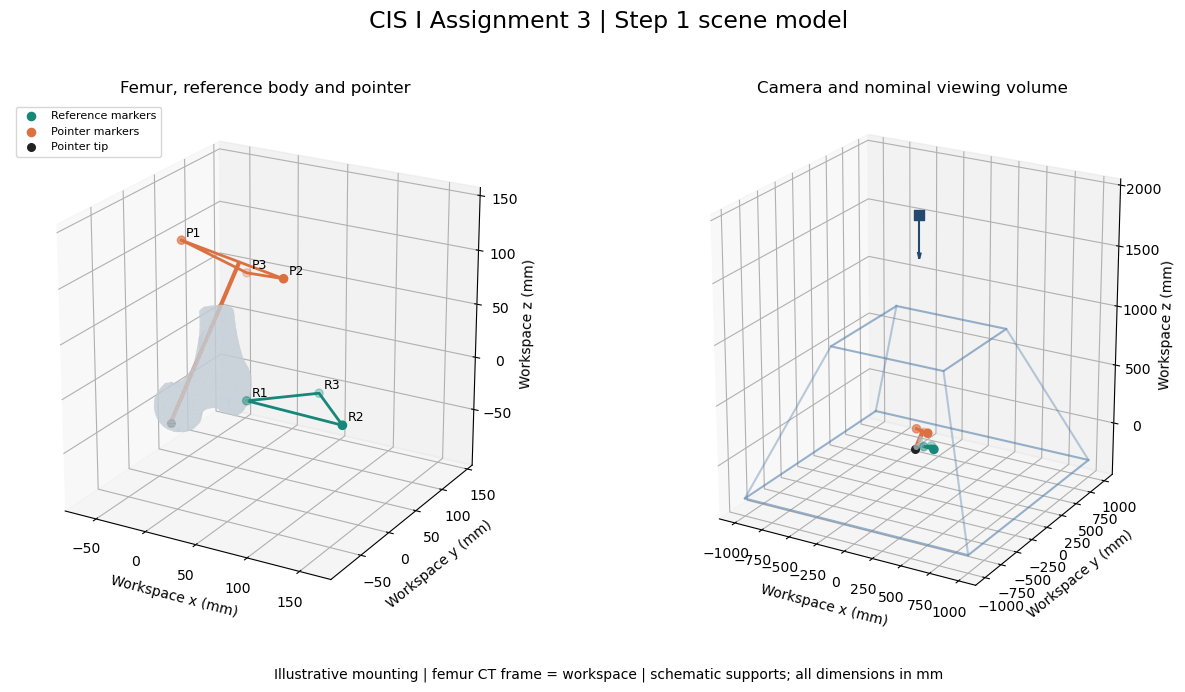

In [3]:
fig = plot_scene()
plt.show()